# 02 · Compliance Auditor: end-to-end fine-tuning on Kaggle (T4)

A single notebook that covers the whole journey:

| Step | What it does | Duration on T4 (estimate, Qwen3-4B) |
|---|---|---|
| A. Data | builds the dataset from KICS (identical to notebook 01) | ~2 min |
| B. Model | loads the model and adds the LoRA adapters | ~3 min |
| C. Baseline | the untrained model on `test` and `test_ood` (the numbers to beat) | ~15 min |
| D. Reasoning *(optional)* | the model reasons on the train examples; only the correct ones are kept | ~1–2 h |
| E. Fine-tuning | SFT with LoRA, loss on the answer only | ~1.5–2.5 h |
| F. Final evaluation | the trained model on the same splits + comparison | ~15 min |
| G. Export | LoRA adapter + GGUF + Modelfile for Ollama | ~15 min |

## Kaggle settings

1. *File* → *Import Notebook* and upload this file.
2. In the *Settings* panel:
   - **Accelerator: GPU T4 x2.** The notebook uses a single T4. P100 does not work, because Unsloth needs a newer GPU.
   - **Internet: On**, which requires a phone-verified account.
3. **Quick check:** first run interactively with `EVAL_LIMIT = 20` and `NUM_EPOCHS = 0.05`. If everything works, go back to the defaults and start *Save Version* → *Save & Run All*. The run keeps going in the background (up to 12 hours), even if you close the browser.

Results land in `/kaggle/working/auditor_run/<preset>/`: `metrics.json` (every metric, including precision/recall/f1 per label), `results.md`, `epoch_metrics.csv` (the `val` metrics after every training epoch), `example_runs.md` (2-3 answers from the trained model), the predictions, the LoRA adapter (`lora_adapter/` for the last epoch, `lora_adapter_best/` for the best one on `val`), the GGUF file, and `OLLAMA_README.md`.

## Models (the `PRESET` variable)

| Preset | Model | Thinking? | On T4 | On a laptop (Ollama) |
|---|---|---|---|---|
| `qwen3-4b` **(default)** | Qwen3-4B | on / off | 4-bit (QLoRA); the smallest preset, so usually also the fastest | yes |
| `qwen3.5-4b` | Qwen3.5-4B (newer) | on / off | 4-bit; on a T4, Unsloth trains it in float32 (fp16 produces NaN), so ~3x slower | yes |
| `qwen3-14b` | Qwen3-14B | on / off | 4-bit, 2048 context, slow | no, no GGUF export |
| `llama3.1-8b` | Llama 3.1 8B Instruct | no | 4-bit | partly on CPU, slower |
| `phi-4` | Phi-4 14B | no | 4-bit, 2048 context, slow | no, no GGUF export |
| `gemma3-4b` | Gemma 3 4B | no | 4-bit; GGUF only as Q8_0 (Unsloth has no Q4 for Gemma yet) | yes |
| `deepseek-r1-8b` | DeepSeek-R1-0528-Qwen3-8B | always | 4-bit; answers include the reasoning, so evaluation is slow | partly on CPU, slower |

- **Models without thinking** (Llama, Phi-4, Gemma) ignore `RUN_REASONING` and are evaluated with a direct answer only.
- **DeepSeek-R1 always reasons:** it is automatically trained on reasoning traces and evaluated only in thinking mode.
- **Licenses:** Qwen is Apache-2.0, and Phi-4 and DeepSeek are MIT. Llama 3.1 has the *Llama 3.1 Community License*, and Gemma 3 has the *Gemma Terms of Use*; mention them in the report.

For a comparison across families, run the notebook several times, with a different `PRESET` each time. Each run writes its results to its own folder.

## The two training variants (Qwen)

- **`RUN_REASONING = False` (default):** the model learns to answer directly with the JSON verdict.
- **`RUN_REASONING = True`:** the model reasons first on the train examples. Only the reasoning traces that reach the correct verdict and the correct lines, checked automatically against the KICS labels, are kept and trained on. The result is a model that reasons before the verdict. This variant adds ~2–3 hours.

## LoRA, or just the temperature?

- **The fine-tuning here is already LoRA.** The base model stays frozen, and only the small adapters are trained. At `LORA_R = 16` that is 33M parameters for Qwen3-4B, 42M for Llama 3.1 8B, and 65M for Phi-4, i.e. 0.4–0.8% of the model (this notebook uses `LORA_R = 8`, roughly half as many). Training still takes hours, because every example still passes through every layer of the model, forward and backward. LoRA cuts the memory needed by a lot, but the compute only a little.
- **The temperature trains nothing.** It only decides how random the model's next-word choice is when it generates (0 = always the likeliest word). It does not teach it the KICS rules, the JSON format, or how to cite lines.

| Variant | What you set in the config cell | What you get |
|---|---|---|
| **No training** | `RUN_TRAINING = False`, `RUN_FINAL_EVAL = False`, `RUN_GGUF_EXPORT = False`, `TEMPERATURE_SWEEP = [0.0, 0.3, 0.7]` | the base model's scores, with the best temperature, and a `Modelfile` for the original model in Ollama |
| **Short LoRA** | `NUM_EPOCHS = 1` | LoRA adapter + GGUF; training takes about half as long |
| **Full LoRA** (default) | `NUM_EPOCHS = 5` | LoRA adapter + GGUF, plus `lora_adapter_best/` (see below) |

**More epochs means a risk of memorising, not just more time.** The training cell (E) runs the model on `EPOCH_EVAL_LIMIT` examples from `val` after every epoch, plots a chart of `macro_f1`, `recall_non_compliant`, `f1_insufficient`, `line_recall`, `json_valid`, and `train_loss`, and writes it all to `epoch_metrics.csv`. The adapter from the epoch with the best `macro_f1` is saved separately to `lora_adapter_best/`; `lora_adapter/` (used downstream for the export) stays the last epoch's. If the chart shows `macro_f1` dropping on `val` while `train_loss` keeps dropping, the model has started memorising the examples, and you can use `lora_adapter_best/` instead of the last epoch.

`TEMPERATURE_SWEEP` tries every temperature on `SWEEP_LIMIT` examples from `val` and keeps the best one, separately for the base model and the trained one. The choice is made on `val`, not on `test`, so the test scores are not inflated. The temperature used shows up in the results table and makes it into the `Modelfile`. For direct answers, 0 or a small value usually wins. For DeepSeek-R1 it is tried in thinking mode, which is slow, so use at most 2 values (e.g. `[0.4, 0.6]`).


In [1]:
import os
from pathlib import Path

# On Kaggle's "GPU T4 x2", the device order PyTorch sees can disagree with the physical PCI order, which has
# caused "tensors on different devices" errors for other Unsloth users; both lines below must run before any
# CUDA/Unsloth call (https://github.com/unslothai/unsloth/issues/508) and are a no-op once CUDA is already
# initialised, so after a crash, restart the kernel (not just re-run cell 1) before trying again.
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # one T4 is enough; hiding the second one avoids multi-GPU surprises
os.environ["UNSLOTH_DISABLE_FAST_GENERATION"] = "1"  # https://unsloth.ai/docs/basics/unsloth-environment-flags

PRESET = "qwen3-4b"     # one of the PRESETS below

RUN_BASELINE = False    # skip the untrained-model baseline entirely, straight to fine-tuning (no GPU time spent on it)
RUN_REASONING = False   # direct JSON answers only, no reasoning - this variant is pure non-reasoning
RUN_TRAINING = True     # SFT with LoRA
RUN_FINAL_EVAL = True   # fine-tuned model on test / test_ood
RUN_GGUF_EXPORT = True  # GGUF + Ollama Modelfile for the laptop demo

EVAL_LIMIT = None              # None = the whole split; e.g. 20 for a quick check
THINKING_EVAL_LIMIT = 150      # reasoning answers are long, so they are scored on a subset
REASONING_SAMPLES = 800        # train examples the model reasons about when RUN_REASONING = True
REASONING_MIN_FRACTION = 0.75  # share of reasoning examples in the training mix (Unsloth's advice for thinking models)
DIRECT_MAX_NEW_TOKENS = 512
THINKING_MAX_NEW_TOKENS = 1536

# Decoding: how an answer is picked at generation time. It never changes the model, so it is not training.
# temperature 0 = greedy (always the likeliest token); higher values make the answers more random.
DIRECT_SAMPLING = dict(temperature=0.0, top_p=1.0, top_k=0)      # top_p 1.0 and top_k 0 switch those filters off
THINKING_SAMPLING = dict(temperature=0.6, top_p=0.95, top_k=20)  # the makers' advice: greedy reasoning repeats itself
TEMPERATURE_SWEEP = []  # e.g. [0.0, 0.3, 0.7]: each value is scored on val and the best one is used on test
SWEEP_LIMIT = 100       # val examples per temperature

NUM_EPOCHS = 3          # lowered from 5: val macro_f1 peaked around epoch 2 last run, not epoch 5
EPOCH_EVAL_LIMIT = 60   # val examples scored after every training epoch, to plot progress live
LEARNING_RATE = 7e-5    # lowered further from 1e-4: no reasoning means the loss signal is 100% on a short,
                        # templated JSON answer, which is even easier to memorize too fast than with reasoning mixed in
LORA_R = 8              # halved from 16: fewer adapter parameters to memorize the sparse ~2/rule KICS data
LORA_DROPOUT = 0.1      # raised further from 0.05: extra regularization for this smaller, no-reasoning run
SEED = 3407

QWEN = dict(loader="language", transformers="4.57.6", thinking="hybrid", chat_template=None,
            instruction="<|im_start|>user\n", response="<|im_start|>assistant\n", stop=["<|im_end|>", "<|endoftext|>"])
PRESETS = {
    # A 16-bit load used 14.24 of 14.56 GB on a real T4 run, just from loading plus a 2-example smoke test
    # (no training yet): too little headroom. 4-bit (QLoRA) leaves far more room, at some training speed cost.
    "qwen3-4b": {**QWEN, "model": "unsloth/Qwen3-4B", "load_in_4bit": True, "max_seq_len": 4096, "batch": 2,
                 "grad_accum": 8, "gguf": "q4_k_m", "ollama": "qwen3:4b"},
    # On a T4 Unsloth trains Qwen3.5 in float32 (it produces NaNs in float16); 4-bit weights keep it in memory.
    "qwen3.5-4b": {**QWEN, "model": "unsloth/Qwen3.5-4B", "load_in_4bit": True, "max_seq_len": 4096, "batch": 1,
                   "grad_accum": 16, "gguf": "q4_k_m", "ollama": "qwen3.5:4b", "transformers": "5.15.1"},
    "qwen3-14b": {**QWEN, "model": "unsloth/Qwen3-14B", "load_in_4bit": True, "max_seq_len": 2048, "batch": 1,
                  "grad_accum": 16, "gguf": None, "ollama": "qwen3:14b"},
    "llama3.1-8b": dict(model="unsloth/meta-Llama-3.1-8B-Instruct", loader="language", load_in_4bit=True,
                        max_seq_len=4096, batch=1, grad_accum=16, transformers="4.57.6", thinking="none",
                        chat_template="llama-3.1", gguf="q4_k_m", ollama="llama3.1:8b",
                        instruction="<|start_header_id|>user<|end_header_id|>\n\n",
                        response="<|start_header_id|>assistant<|end_header_id|>\n\n",
                        stop=["<|eot_id|>", "<|end_of_text|>", "<|eom_id|>"]),
    "phi-4": dict(model="unsloth/Phi-4", loader="language", load_in_4bit=True, max_seq_len=2048, batch=1,
                  grad_accum=16, transformers="4.57.6", thinking="none", chat_template="phi-4", gguf=None,
                  ollama="phi4:14b", instruction="<|im_start|>user<|im_sep|>",
                  response="<|im_start|>assistant<|im_sep|>", stop=["<|im_end|>", "<|endoftext|>"]),
    # Gemma 3 loads through FastModel; Unsloth exports it to GGUF only as Q8_0 / F16 / BF16 for now.
    "gemma3-4b": dict(model="unsloth/gemma-3-4b-it", loader="model", load_in_4bit=True, max_seq_len=4096, batch=1,
                      grad_accum=16, transformers="4.57.6", thinking="none", chat_template="gemma-3", gguf="Q8_0",
                      ollama="gemma3:4b", instruction="<start_of_turn>user\n", response="<start_of_turn>model\n",
                      stop=["<end_of_turn>", "<eos>"]),
    # Always reasons, and its chat template drops the reasoning from assistant turns,
    # which is why training texts are built from the generation prompt (section E).
    "deepseek-r1-8b": dict(model="unsloth/DeepSeek-R1-0528-Qwen3-8B", loader="language", load_in_4bit=True,
                           max_seq_len=4096, batch=1, grad_accum=16, transformers="4.57.6", thinking="always",
                           # R1-style models reason at length (DeepSeek's own card reports 12K-23K tokens
                           # on hard math); 2048 left 0/800 traces complete. This is still a guess, not verified
                           # on a real GPU, and may need to go higher still if 0 are kept again.
                           chat_template=None, gguf="q4_k_m", ollama="deepseek-r1:8b", think_tokens=3200,
                           instruction="<\uff5cUser\uff5c>", response="<\uff5cAssistant\uff5c>",
                           stop=["<\uff5cend\u2581of\u2581sentence\uff5c>"]),
}
CFG = PRESETS[PRESET]
THINKING = CFG["thinking"]  # "hybrid" = thinking can be switched on/off, "always", or "none"
THINK_TOKENS = CFG.get("think_tokens", THINKING_MAX_NEW_TOKENS)
if THINKING == "none" and RUN_REASONING:
    print(f"{PRESET} has no thinking mode, so RUN_REASONING is turned off.")
    RUN_REASONING = False
if THINKING == "always" and not RUN_REASONING:
    print(f"{PRESET} always reasons, so it is trained on reasoning traces (RUN_REASONING = True).")
    RUN_REASONING = True

DRY_RUN = os.environ.get("E2E_DRY_RUN") == "1"  # local CPU check of the pipeline: no install, no GPU, fake answers
ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or (os.name == "posix" and Path("/kaggle/working").is_dir())
WORK_DIR = Path(os.environ.get("KICS_WORKDIR", "/kaggle/working" if ON_KAGGLE else "."))
RUN_DIR = WORK_DIR / "auditor_run" / PRESET
RUN_DIR.mkdir(parents=True, exist_ok=True)
import time


LOG_PATH = RUN_DIR / "run_log.txt"


def log(*parts, sep=" "):
    """Prints and also appends a timestamped line to RUN_DIR/run_log.txt, so section/epoch markers
    survive even after plot_epoch_progress()'s clear_output(wait=True) wipes a cell's earlier output,
    and the whole run's timeline stays readable afterwards, from the saved results."""
    message = sep.join(str(p) for p in parts)
    print(message)
    with open(LOG_PATH, "a", encoding="utf-8") as f:
        f.write(f"[{time.strftime('%Y-%m-%d %H:%M:%S')}] {message}\n")


log(f"Preset {PRESET}: {CFG['model']} | thinking: {THINKING} | {'Kaggle' if ON_KAGGLE else 'local'}"
    f"{' | DRY RUN' if DRY_RUN else ''}")
log("Outputs:", RUN_DIR.resolve())
log(f"Flags: RUN_BASELINE={RUN_BASELINE} | RUN_REASONING={RUN_REASONING} | RUN_TRAINING={RUN_TRAINING} | "
    f"RUN_FINAL_EVAL={RUN_FINAL_EVAL} | RUN_GGUF_EXPORT={RUN_GGUF_EXPORT}")
log(f"Training: {NUM_EPOCHS} epochs | lr={LEARNING_RATE} | lora_dropout={LORA_DROPOUT} | "
    f"reasoning_samples={REASONING_SAMPLES if RUN_REASONING else '-'}")

Preset qwen3-4b: unsloth/Qwen3-4B | thinking: hybrid | Kaggle
Outputs: /kaggle/working/auditor_run/qwen3-4b
Flags: RUN_BASELINE=False | RUN_REASONING=False | RUN_TRAINING=True | RUN_FINAL_EVAL=True | RUN_GGUF_EXPORT=True
Training: 3 epochs | lr=7e-05 | lora_dropout=0.1 | reasoning_samples=-


## Installation

The same recipe as the official Unsloth notebooks for Kaggle. Keeps Kaggle's own `torch` and `numpy` versions and pins `transformers` and `trl`. Takes 2–4 minutes.

In [2]:
import subprocess


def sh(cmd):
    result = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-3000:], result.stderr[-3000:], sep="\n")
        raise RuntimeError(f"Command failed: {cmd}")


if DRY_RUN:
    print("DRY RUN: skipping installation")
else:
    log("=== Installing dependencies (unsloth, trl, transformers...) - a few minutes ===")
    # Upgrading Kaggle's torch pulls a CUDA build that its torchaudio cannot import, so the current versions are pinned.
    try:
        import numpy, PIL, torch, torchvision
        pins = (f"numpy=={numpy.__version__} pillow=={PIL.__version__} torch=={torch.__version__.split('+')[0]} "
                f"torchvision=={torchvision.__version__.split('+')[0]}")
    except Exception:
        pins = "numpy pillow torch torchvision"
    sh("pip install --upgrade -qqq uv")
    sh(f"uv pip install -qqq {pins} bitsandbytes xformers unsloth")
    sh('uv pip install -qqq triton "huggingface_hub>=0.34.0" "datasets==4.3.0"')
    sh('uv pip install -qqq --no-deps --upgrade "torchao>=0.16.0"')
    sh(f"uv pip install -qqq transformers=={CFG['transformers']}")
    sh("uv pip install -qqq --no-deps trl==0.22.2")
    print("Installation done.")

=== Installing dependencies (unsloth, trl, transformers...) - a few minutes ===
Installation done.


## A. The KICS data

The code below is the one from notebook 01, already tested. It uses the same KICS version and the same seed, so it produces exactly the same dataset. The full explanations are in notebook 01.

In [3]:
import collections
import hashlib
import json
import random
import re
import shutil
from datetime import datetime, timezone

import pandas as pd

KICS_REPO = "https://github.com/Checkmarx/kics.git"
KICS_REF = "v2.2.1"
PLATFORMS = {"terraform": (".tf",), "k8s": (".yaml", ".yml", ".json")}
EXCLUDED_CATEGORIES = {"Bill Of Materials"}
EXCLUDED_QUERY_NAMES = {"Name Is Not Snake Case", "Metadata Label Is Invalid"}
HOLDOUT_PROVIDERS = {"gcp"}
SPLIT_RATIOS = {"train": 0.8, "val": 0.1, "test": 0.1}
IRRELEVANT_PER_QUERY = 1
MAX_CHARS = 8000
DATA_SEED = 42  # same seed as notebook 01, so both build the same dataset

KICS_DIR = Path("/tmp/kics_repo") if ON_KAGGLE else WORK_DIR / "kics_repo"
OUT_DIR = WORK_DIR / "auditor_run" / "kics_dataset"
OUT_DIR.mkdir(parents=True, exist_ok=True)
log("=== A. Building the KICS dataset ===")
print("KICS_DIR:", KICS_DIR.resolve())
print("OUT_DIR: ", OUT_DIR.resolve())

=== A. Building the KICS dataset ===
KICS_DIR: /tmp/kics_repo
OUT_DIR:  /kaggle/working/auditor_run/kics_dataset


In [4]:
def git(*args, cwd=None):
    result = subprocess.run(["git", "-c", "core.longpaths=true", *args], cwd=cwd, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f"git {' '.join(args)} failed:\n{result.stderr}")
    return result.stdout.strip()


sparse_paths = [f"assets/queries/{platform}" for platform in PLATFORMS]
if not (KICS_DIR / ".git").exists():
    print(f"Cloning KICS {KICS_REF} (only {', '.join(sparse_paths)}) ...")
    try:
        git("clone", "--depth", "1", "--branch", KICS_REF, "--filter=blob:none", "--sparse", KICS_REPO, str(KICS_DIR))
    except RuntimeError as exc:
        raise RuntimeError(
            f"{exc}\nCannot reach GitHub. On Kaggle: Settings -> Internet -> On "
            "(requires a phone-verified account), then run the notebook again."
        ) from None
git("sparse-checkout", "set", *sparse_paths, cwd=KICS_DIR)
KICS_COMMIT = git("rev-parse", "HEAD", cwd=KICS_DIR)
print("KICS commit:", KICS_COMMIT)

Cloning KICS v2.2.1 (only assets/queries/terraform, assets/queries/k8s) ...
KICS commit: 28e01700646273c1a959d5c53eac4b1aa3834477


In [5]:
FILENAME_KEYS = ("fileName", "filename", "fineName")
TF_RESOURCE_RE = re.compile(r'^[ \t]*resource[ \t]+"([^"]+)"[ \t]+"([^"]+)"', re.M)
TF_MODULE_RE = re.compile(r'^[ \t]*module[ \t]+"', re.M)
K8S_KIND_RE = re.compile(r'^[ \t-]*"?kind"?[ \t]*:[ \t]*"?([A-Za-z]+)"?', re.M)


def read_text(path):
    return path.read_text(encoding="utf-8", errors="replace").lstrip("\ufeff").replace("\r\n", "\n")


def resource_types(code, platform):
    if platform == "terraform":
        return sorted({rtype for rtype, _ in TF_RESOURCE_RE.findall(code)})
    return sorted(set(K8S_KIND_RE.findall(code)))


def violation_lines(test_dir, positive_files):
    """Maps each positive file to its violation lines; also returns how many result items could not be attributed."""
    path = test_dir / "positive_expected_result.json"
    items = json.loads(read_text(path)) if path.exists() else []
    lines, unattributed = collections.defaultdict(set), 0
    for item in items:
        name = next((item[key] for key in FILENAME_KEYS if key in item), None)
        if name is None and len(positive_files) == 1:
            name = positive_files[0]
        if "line" in item and name is not None and Path(name).name in positive_files:
            lines[Path(name).name].add(int(item["line"]))
        else:
            unattributed += 1
    return {name: sorted(found) for name, found in lines.items()}, unattributed


def is_data_file(path, exts):
    return path.is_file() and path.suffix in exts and "expected_result" not in path.name


records, skipped = [], collections.Counter()
queries_root = KICS_DIR / "assets" / "queries"
for platform, exts in PLATFORMS.items():
    for md_path in sorted((queries_root / platform).rglob("metadata.json")):
        if "test" in md_path.relative_to(queries_root).parts:
            continue
        query_dir, test_dir = md_path.parent, md_path.parent / "test"
        md = json.loads(read_text(md_path))
        if md.get("category") in EXCLUDED_CATEGORIES or md.get("queryName") in EXCLUDED_QUERY_NAMES:
            skipped["rule_excluded"] += 1
            continue
        if not test_dir.is_dir():
            skipped["rule_without_tests"] += 1
            continue
        rel = query_dir.relative_to(queries_root / platform).parts
        query_id = md.get("id") or "/".join(rel)
        files = sorted(p.name for p in test_dir.iterdir() if is_data_file(p, exts))
        positives = [f for f in files if f.lower().startswith("positive")]
        negatives = [f for f in files if f.lower().startswith("negative")]
        skipped["nested_multi_file_test"] += sum(
            1 for p in test_dir.rglob("*") if p.parent != test_dir and is_data_file(p, exts)
        )
        vlines, unattributed = violation_lines(test_dir, positives)
        skipped["unattributed_result_item"] += unattributed
        rego_path = query_dir / "query.rego"
        rego = read_text(rego_path) if rego_path.exists() else ""
        for fname in positives + negatives:
            code = read_text(test_dir / fname)
            is_positive = fname in positives
            if is_positive and not vlines.get(fname):
                skipped["positive_without_lines"] += 1
            elif "kics-scan" in code:
                skipped["kics_scan_annotation"] += 1
            elif len(code) > MAX_CHARS:
                skipped["too_long"] += 1
            else:
                records.append({
                    "sample_id": f"{query_id}:{fname}",
                    "query_id": query_id,
                    "query_name": md.get("queryName", ""),
                    "requirement": " ".join((md.get("descriptionText") or md.get("queryName", "")).split()),
                    "severity": md.get("severity", ""),
                    "category": md.get("category", ""),
                    "cwe": md.get("cwe", ""),
                    "description_url": md.get("descriptionUrl", ""),
                    "platform": platform,
                    "provider": rel[0] if platform == "terraform" else "k8s",
                    "query_path": f"assets/queries/{platform}/{'/'.join(rel)}",
                    "source_file": fname,
                    "label": "non_compliant" if is_positive else "compliant",
                    "violation_lines": vlines.get(fname, []),
                    "code_raw": code,
                    "has_module": bool(TF_MODULE_RE.search(code)),
                    "resource_types": resource_types(code, platform),
                    "rego": rego,
                })

df = pd.DataFrame(records)
print("Skipped:", dict(skipped))
print(f"Rules: {df.query_id.nunique()} | samples: {len(df)}")
df.groupby(["platform", "label"]).size().unstack(fill_value=0)

Skipped: {'nested_multi_file_test': 78, 'unattributed_result_item': 5, 'positive_without_lines': 11, 'rule_excluded': 20, 'too_long': 8}
Rules: 883 | samples: 3162


label,compliant,non_compliant
platform,,
k8s,261,270
terraform,1196,1435


In [6]:
HEREDOC_RE = re.compile(r'<<-?[ \t]*"?([A-Za-z_][A-Za-z0-9_]*)"?[ \t]*$')
YAML_BLOCK_RE = re.compile(r"(?::|^[ \t]*-)[ \t]*[|>][-+0-9]*[ \t]*$")
LABEL_TOKEN_RE = re.compile(r"[A-Za-z0-9_\-]*(?:positive|negative)[A-Za-z0-9_\-]*", re.I)
HINT_WORDS = {"good", "bad", "secure", "insecure", "wrong", "correct", "compliant", "noncompliant",
              "vulnerable", "pass", "passing", "fail", "failing"}
TF_TYPED_BLOCK_RE = re.compile(r'^([ \t]*(resource|data)[ \t]+"([^"]+)"[ \t]+")([^"]+)"', re.M)
TF_NAMED_BLOCK_RE = re.compile(r'^([ \t]*(module|variable|output)[ \t]+")([^"]+)"', re.M)
TF_NAME_ATTR_RE = re.compile(r'^([ \t]*name[ \t]*=[ \t]*")([^"$\n]+)("[ \t]*)$', re.M)
REF_PREFIX = {"resource": "", "data": "data.", "module": "module.", "variable": "var."}
NAME_CHECK_RE = re.compile(r"\.name\b\s*(?:==|!=)|\(\s*[^()]*\.name\s*[,)]")  # Rego that inspects `name` values
NAME_VALUE_RE = re.compile(
    r"""^[ \t-]*["']?(?:name|bucket|domain_name|creation_token|sid|identifier|cluster_identifier|function_name|title)["']?"""
    r"""[ \t]*[:=][ \t]*["']?([^"'\n,]+?)["']?[ \t]*,?[ \t]*$""",
    re.I | re.M,
)
KEY_RE = re.compile(r'^[ \t-]*"?([A-Za-z0-9_\-.]+)"?[ \t]*(?:[:=]|\{)', re.M)


def strip_hcl_comments(code):
    out, in_block, heredoc = [], False, None
    for line in code.split("\n"):
        if heredoc is not None:
            out.append(line)
            if line.strip() == heredoc:
                heredoc = None
            continue
        buf, in_str, i = [], False, 0
        while i < len(line):
            ch, nxt = line[i], line[i + 1:i + 2]
            if in_block:
                if ch == "*" and nxt == "/":
                    in_block = False
                    i += 1
            elif in_str:
                buf.append(ch)
                if ch == "\\":
                    buf.append(nxt)
                    i += 1
                elif ch == '"':
                    in_str = False
            elif ch == "#" or (ch == "/" and nxt == "/"):
                break
            elif ch == "/" and nxt == "*":
                in_block = True
                i += 1
            else:
                buf.append(ch)
                in_str = ch == '"'
            i += 1
        line = "".join(buf).rstrip()
        out.append(line)
        match = HEREDOC_RE.search(line)
        if match and not in_block:
            heredoc = match.group(1)
    return "\n".join(out)


def strip_yaml_comments(code):
    out, block_indent = [], None
    for line in code.split("\n"):
        indent = len(line) - len(line.lstrip(" "))
        if block_indent is not None and (not line.strip() or indent > block_indent):
            out.append(line)  # inside a literal block scalar: '#' is content, not a comment
            continue
        block_indent, buf, quote = None, [], None
        for i, ch in enumerate(line):
            if quote:
                quote = None if ch == quote else quote
            elif ch in "\"'" and (i == 0 or line[i - 1] in " \t:-[{,"):
                quote = ch
            elif ch == "#" and (i == 0 or line[i - 1] in " \t"):
                break
            buf.append(ch)
        line = "".join(buf).rstrip()
        out.append(line)
        if YAML_BLOCK_RE.search(line):
            block_indent = indent
    return "\n".join(out)


def has_hint(name):
    return bool(HINT_WORDS & set(re.split(r"[^a-z]+", name.lower())))


def rename_tf_labels(code, fresh):
    """Renames every Terraform block label together with its references (type.label, data.type.label, module.x, var.x)."""
    blocks = sorted(
        [(m.start(), m.group(2), m.group(3), m.group(4)) for m in TF_TYPED_BLOCK_RE.finditer(code)]
        + [(m.start(), m.group(2), "", m.group(3)) for m in TF_NAMED_BLOCK_RE.finditer(code)]
    )
    table = {}
    for _, kind, rtype, label in blocks:
        if (kind, rtype, label) not in table:
            table[(kind, rtype, label)] = fresh(label)
    code = TF_TYPED_BLOCK_RE.sub(lambda m: f'{m.group(1)}{table[(m.group(2), m.group(3), m.group(4))]}"', code)
    code = TF_NAMED_BLOCK_RE.sub(lambda m: f'{m.group(1)}{table[(m.group(2), "", m.group(3))]}"', code)
    for (kind, rtype, label), new in table.items():
        if kind != "output":
            scope = REF_PREFIX[kind] + (f"{rtype}." if rtype else "")
            code = re.sub(rf"(?<![\w.\-]){re.escape(scope + label)}(?![\w\-])", scope + new, code)
    return code


def hcl_line_depths(code):
    """Brace depth at the start of each line (strings and heredocs ignored)."""
    depths, depth, heredoc = [], 0, None
    for line in code.split("\n"):
        depths.append(depth)
        if heredoc is not None:
            if line.strip() == heredoc:
                heredoc = None
            continue
        in_str, prev = False, ""
        for ch in line:
            if in_str:
                in_str = not (ch == '"' and prev != "\\")
            elif ch == '"':
                in_str = True
            elif ch == "{":
                depth += 1
            elif ch == "}":
                depth = max(depth - 1, 0)
            prev = ch
        match = HEREDOC_RE.search(line)
        if match:
            heredoc = match.group(1)
    return depths


def rename_tf_name_values(code, fresh):
    """Renames top-level `name = "..."` literals that occur nowhere else in the file.
    Nested `name` keys (e.g. RDS `parameter { name = "log_connections" }`) carry meaning and are kept."""
    lines, depths = code.split("\n"), hcl_line_depths(code)
    top_level = collections.defaultdict(list)
    for i, line in enumerate(lines):
        match = TF_NAME_ATTR_RE.match(line)
        if match and depths[i] == 1:
            top_level[match.group(2)].append(i)
    for value, idxs in top_level.items():
        if len(re.findall(rf"(?<![\w\-]){re.escape(value)}(?![\w\-])", code)) == len(idxs):
            new = fresh(value)
            for i in idxs:
                lines[i] = TF_NAME_ATTR_RE.sub(lambda m: m.group(1) + new + m.group(3), lines[i])
    return "\n".join(lines)


def neutralize_names(code, platform, vocab, rename_name_values=True):
    prefix = next(p for p in ("res", "obj", "item", "node", "elem") if not re.search(rf"\b{p}\d+\b", code))
    renamed = []

    def fresh(original):
        renamed.append(original)
        return f"{prefix}{len(renamed)}"

    if platform == "terraform":
        code = rename_tf_labels(code, fresh)
        if rename_name_values:
            code = rename_tf_name_values(code, fresh)
    leaky = [m.group(0) for m in LABEL_TOKEN_RE.finditer(code)]
    if rename_name_values:
        leaky += [n for n in NAME_VALUE_RE.findall(code) if has_hint(n) and not re.search(r"[.$(\[{]", n)]
    replacements = {name: fresh(name) for name in dict.fromkeys(leaky) if name not in vocab}
    for name in sorted(replacements, key=len, reverse=True):
        code = re.sub(rf"(?<![A-Za-z0-9_\-]){re.escape(name)}(?![A-Za-z0-9_\-])", replacements[name], code)
    return code, renamed


def sanitize(code, platform, source_file, vocab, rename_name_values=True):
    if platform == "terraform":
        code = strip_hcl_comments(code)
    elif not source_file.endswith(".json"):
        code = strip_yaml_comments(code)
    return neutralize_names(code, platform, vocab, rename_name_values)


name_sensitive = {q for q, rego in zip(df.query_id, df.rego) if NAME_CHECK_RE.search(rego)}
print(f"Rules whose Rego inspects `name` (their name values are kept): {len(name_sensitive)}")
vocab = {key for code in df.code_raw for key in KEY_RE.findall(code)}  # attribute/key names are never renamed
cleaned = [sanitize(r.code_raw, r.platform, r.source_file, vocab, r.query_id not in name_sensitive)
           for r in df.itertuples()]
df["code"] = [code for code, _ in cleaned]
df["renamed"] = [names for _, names in cleaned]
assert (df.code.str.count("\n") == df.code_raw.str.count("\n")).all(), "sanitizing must keep line numbers"


def cited_lines_ok(code, lines):
    rows = code.split("\n")
    return all(1 <= n <= len(rows) and rows[n - 1].strip() for n in lines)


ok = [cited_lines_ok(c, v) for c, v in zip(df.code, df.violation_lines)]
skipped["violation_line_blank_or_out_of_range"] += len(ok) - sum(ok)
df = df[ok].reset_index(drop=True)

df["code_hash"] = df.code.map(lambda c: hashlib.sha1(c.encode("utf-8")).hexdigest()[:16])
conflict = df.groupby(["query_id", "code_hash"]).label.transform("nunique") > 1
duplicate = df.duplicated(["query_id", "code_hash"]) & ~conflict
skipped["conflicting_labels_after_sanitizing"] += int(conflict.sum())
skipped["duplicate_after_sanitizing"] += int(duplicate.sum())
df = df[~conflict & ~duplicate].reset_index(drop=True)
print(f"Samples after sanitizing and de-duplication: {len(df)}")

LABEL_WORD_RE = re.compile(r"(?i)positive|negative")
HINT_RE = re.compile(r"(?i)\b(?:" + "|".join(sorted(HINT_WORDS)) + r")\b")
COMMENT_RE = re.compile(r"(?m)^[ \t]*(?:#|//|/\*)")


def leak_report(column):
    by_label = df.groupby("label")[column]
    return (pd.DataFrame({
        "% files with positive/negative": by_label.apply(lambda s: s.str.contains(LABEL_WORD_RE).mean()),
        "% files with hint words": by_label.apply(lambda s: s.str.contains(HINT_RE).mean()),
        "% files with comment lines": by_label.apply(lambda s: s.str.contains(COMMENT_RE).mean()),
    }) * 100).round(1)


print("\nBEFORE sanitizing")
display(leak_report("code_raw"))
print("AFTER sanitizing")
display(leak_report("code"))

Rules whose Rego inspects `name` (their name values are kept): 183
Samples after sanitizing and de-duplication: 3160

BEFORE sanitizing


,% files with positive/negative,% files with hint words,% files with comment lines
label,,,
compliant,47.6,3.4,11.5
non_compliant,44.3,1.8,14.3


AFTER sanitizing


,% files with positive/negative,% files with hint words,% files with comment lines
label,,,
compliant,0.0,0.4,0.1
non_compliant,0.0,0.7,0.3


In [7]:
CATEGORY_TO_REGULATION = {
    "Encryption": ["GDPR Art. 32(1)(a)", "AI Act Art. 15(5)"],
    "Access Control": ["GDPR Art. 25(2)", "GDPR Art. 32(1)(b)", "AI Act Art. 15(5)"],
    "Networking and Firewall": ["GDPR Art. 32(1)(b)", "AI Act Art. 15(5)"],
    "Secret Management": ["GDPR Art. 32(1)(b)", "AI Act Art. 15(5)"],
    "Insecure Configurations": ["GDPR Art. 32(1)(b)"],
    "Insecure Defaults": ["GDPR Art. 25(2)", "GDPR Art. 32(1)(b)"],
    "Observability": ["GDPR Art. 32(1)(b)", "AI Act Art. 12"],
    "Backup": ["GDPR Art. 32(1)(c)"],
    "Availability": ["GDPR Art. 32(1)(b)", "AI Act Art. 15(4)"],
}


def assign_split(query_id, provider):
    if provider in HOLDOUT_PROVIDERS:
        return "test_ood"
    u = int(hashlib.sha1(f"{DATA_SEED}:{query_id}".encode()).hexdigest(), 16) % 10_000 / 10_000
    cumulative = 0.0
    for split, ratio in SPLIT_RATIOS.items():
        cumulative += ratio
        if u < cumulative:
            return split
    return split


df["regulation_refs"] = df["category"].map(lambda c: CATEGORY_TO_REGULATION.get(c, []))
df["split"] = [assign_split(q, p) for q, p in zip(df.query_id, df.provider)]
print("Rules per split:", df.drop_duplicates("query_id")["split"].value_counts().to_dict())
pd.crosstab(df["split"], df.label, margins=True)

Rules per split: {'train': 641, 'test': 81, 'test_ood': 81, 'val': 80}


label,compliant,non_compliant,All
split,,,
test,141,175,316
test_ood,131,144,275
train,1030,1227,2257
val,153,159,312
All,1455,1705,3160


In [8]:
TYPE_LITERAL_RE = re.compile(r'"([a-z0-9]+_[a-z0-9_]+)"|resource\.([a-z0-9]+_[a-z0-9_]+)')


def family(resource_type):
    return "_".join(resource_type.split("_")[:2])


tf = df[df.platform == "terraform"]
known_types = set().union(*tf.resource_types.map(set))
REGO_TYPES, RULE_TYPES = {}, {}
for qid, rule in tf.groupby("query_id"):
    rego_types = {a or b for a, b in TYPE_LITERAL_RE.findall(rule.rego.iloc[0])} & known_types
    REGO_TYPES[qid] = sorted(rego_types)
    RULE_TYPES[qid] = sorted(rego_types or set().union(*rule.resource_types.map(set)))

pool = tf[~tf.has_module & (tf.resource_types.map(len) > 0)]
pool_families = pool.resource_types.map(lambda ts: {family(t) for t in ts})
irrelevant = []
for qid, rule in tf.groupby("query_id"):
    first = rule.iloc[0]
    if not REGO_TYPES[qid] or first["provider"] == "kubernetes":
        continue  # generic rules and k8s-in-Terraform rules may apply to resources we cannot rule out
    targets = {family(t) for t in REGO_TYPES[qid]} | {family(t) for ts in rule.resource_types for t in ts}
    candidates = pool[
        (pool["split"] == first["split"])
        & (pool.provider == first["provider"])
        & (pool.query_id != qid)
        & pool_families.map(lambda fams: not fams & targets)
    ]
    rng = random.Random(f"{DATA_SEED}:{qid}")
    for sid in rng.sample(sorted(candidates.sample_id), min(IRRELEVANT_PER_QUERY, len(candidates))):
        evidence = candidates[candidates.sample_id == sid].iloc[0]
        irrelevant.append({
            **first.to_dict(),
            **{k: evidence[k] for k in ["source_file", "code_raw", "code", "code_hash", "has_module", "resource_types", "renamed"]},
            "sample_id": f"{qid}:irrelevant:{sid}",
            "label": "insufficient_evidence",
            "violation_lines": [],
        })

irr = pd.DataFrame(irrelevant)
print(f"Terraform rules with explicit resource types: {sum(map(bool, REGO_TYPES.values()))} / {len(REGO_TYPES)}")
print(f"insufficient_evidence examples: {len(irr)}")
data = pd.concat([df, irr], ignore_index=True)
pd.crosstab(data["split"], data.label, margins=True)

Terraform rules with explicit resource types: 717 / 742
insufficient_evidence examples: 672


label,compliant,insufficient_evidence,non_compliant,All
split,,,,
test,141,57,175,373
test_ood,131,81,144,356
train,1030,473,1227,2730
val,153,61,159,373
All,1455,672,1705,3832


In [9]:
SYSTEM_PROMPT = (
    "You are a compliance auditor. You receive one requirement and one piece of evidence: a configuration file "
    "with numbered lines. Decide whether the evidence shows that the requirement is met.\n"
    "Reply with JSON only, using this schema:\n"
    '{"status": "compliant" | "non_compliant" | "insufficient_evidence", '
    '"citations": [{"file": "<file name>", "line": <line number>, "code": "<exact line>"}], '
    '"rationale": "<short explanation>"}\n'
    "Cite only lines that exist in the evidence. Use insufficient_evidence when the evidence contains nothing "
    "that the requirement applies to."
)


def evidence_name(platform, source_file):
    if platform == "terraform":
        return "main.tf"
    return "manifest.json" if source_file.endswith(".json") else "manifest.yaml"


def numbered(code):
    return "\n".join(f"{n:>4} | {line}" for n, line in enumerate(code.split("\n"), start=1))


def compliant_evidence_lines(row, lines):
    if row.platform == "terraform":
        wanted = set(RULE_TYPES.get(row.query_id, []))
        hits = [n for n, line in enumerate(lines, start=1)
                if (m := TF_RESOURCE_RE.match(line)) and m.group(1) in wanted]
    else:
        hits = [n for n, line in enumerate(lines, start=1) if K8S_KIND_RE.match(line)]
    return hits[:5]


def build_target(row):
    lines = row.code.split("\n")
    file = evidence_name(row.platform, row.source_file)
    if row.label == "non_compliant":
        cited = list(row.violation_lines)
        rationale = f"Requirement not met at line(s) {', '.join(map(str, cited))}: {row.requirement}"
    elif row.label == "compliant":
        cited = compliant_evidence_lines(row, lines)
        rationale = f"The relevant configuration meets the requirement: {row.requirement}"
    else:
        cited = []
        rationale = (f"The requirement concerns {', '.join(REGO_TYPES[row.query_id][:4])}, "
                     f"but the evidence only declares {', '.join(row.resource_types[:4])}.")
    citations = [{"file": file, "line": n, "code": lines[n - 1].strip()} for n in cited]
    return {"status": row.label, "citations": citations, "rationale": rationale}


def build_messages(row):
    user = (f"REQUIREMENT\n{row.requirement}\nCategory: {row.category} | Severity: {row.severity}\n\n"
            f"EVIDENCE: {evidence_name(row.platform, row.source_file)} ({row.platform})\n{numbered(row.code)}")
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user},
        {"role": "assistant", "content": json.dumps(build_target(row), ensure_ascii=False)},
    ]

In [10]:
data["messages"] = [build_messages(row) for row in data.itertuples()]


def to_jsonable(value):
    return value.item() if hasattr(value, "item") else str(value)


def write_jsonl(path, rows):
    with open(path, "w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False, default=to_jsonable) + "\n")


META_COLS = ["sample_id", "query_id", "label", "platform", "provider", "category", "severity"]
sft_dir = OUT_DIR / "sft"
sft_dir.mkdir(exist_ok=True)
for split, group in data.groupby("split"):
    rows = group.sample(frac=1, random_state=DATA_SEED).to_dict("records")
    write_jsonl(sft_dir / f"{split}.jsonl", ({"messages": r["messages"], "meta": {c: r[c] for c in META_COLS}} for r in rows))

SAMPLE_COLS = [c for c in data.columns if c not in ("rego", "messages")]
write_jsonl(OUT_DIR / "kics_samples.jsonl", data[SAMPLE_COLS].to_dict("records"))
QUERY_COLS = ["query_id", "query_name", "requirement", "severity", "category", "cwe", "description_url",
              "platform", "provider", "query_path", "regulation_refs", "split", "rego"]
write_jsonl(OUT_DIR / "kics_queries.jsonl", data.drop_duplicates("query_id")[QUERY_COLS].to_dict("records"))

manifest = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "kics": {"repo": KICS_REPO, "ref": KICS_REF, "commit": KICS_COMMIT},
    "config": {
        "platforms": list(PLATFORMS), "excluded_categories": sorted(EXCLUDED_CATEGORIES),
        "excluded_query_names": sorted(EXCLUDED_QUERY_NAMES), "holdout_providers": sorted(HOLDOUT_PROVIDERS),
        "split_ratios": SPLIT_RATIOS, "irrelevant_per_query": IRRELEVANT_PER_QUERY, "max_chars": MAX_CHARS,
        "seed": DATA_SEED,
    },
    "skipped": dict(skipped),
    "rules": int(data.query_id.nunique()),
    "samples": {split: group.label.value_counts().to_dict() for split, group in data.groupby("split")},
}
(OUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=to_jsonable), encoding="utf-8")
for path in sorted(OUT_DIR.rglob("*.json*")):
    print(f"{str(path.relative_to(OUT_DIR)):28s} {path.stat().st_size / 1e6:6.2f} MB")

kics_queries.jsonl             2.37 MB
kics_samples.jsonl             9.31 MB
manifest.json                  0.00 MB
sft/test.jsonl                 0.82 MB
sft/test_ood.jsonl             0.88 MB
sft/train.jsonl                6.64 MB
sft/val.jsonl                  0.90 MB


In [11]:
assert (data.groupby("query_id")["split"].nunique() == 1).all(), "a rule appears in more than one split"
assert not data.code.str.contains(LABEL_WORD_RE).any(), "positive/negative tokens left in the evidence"
for row in data.itertuples():
    target = json.loads(row.messages[-1]["content"])
    lines = row.code.split("\n")
    assert target["status"] == row.label, row.sample_id
    for c in target["citations"]:
        assert 1 <= c["line"] <= len(lines) and c["code"] and c["code"] == lines[c["line"] - 1].strip(), row.sample_id
    if row.label == "non_compliant":
        assert target["citations"], row.sample_id
    if row.label == "insufficient_evidence":
        assert not target["citations"], row.sample_id
print("All checks passed.\n")

train_hashes = set(data[data["split"] == "train"].code_hash)
for split in ["val", "test", "test_ood"]:
    part = data[data["split"] == split]
    if len(part):
        print(f"{split:9s}: {part.code_hash.isin(train_hashes).mean():6.1%} of evidence files also occur in train (under another rule)")

All checks passed.

val      :   9.9% of evidence files also occur in train (under another rule)
test     :   8.3% of evidence files also occur in train (under another rule)
test_ood :   0.0% of evidence files also occur in train (under another rule)


## B. The model

We load the model chosen in `PRESET` and add the LoRA adapters. The adapters start from zero, so they do not change the answers before training. That means the evaluation in step C measures exactly the base model.

In [12]:
import time

import torch

log("=== B. Loading the model ===")

if DRY_RUN:
    from transformers import AutoTokenizer

    model, tokenizer, LOADER = None, AutoTokenizer.from_pretrained(CFG["model"]), None
else:
    from unsloth import FastLanguageModel, FastModel  # import unsloth before transformers / trl so its patches apply
    from unsloth.chat_templates import get_chat_template
    import transformers
    import trl
    import unsloth

    print(f"unsloth {unsloth.__version__} | transformers {transformers.__version__} | trl {trl.__version__} "
          f"| torch {torch.__version__}")
    gpu = torch.cuda.get_device_properties(0)
    print(f"GPU: {gpu.name}, {gpu.total_memory / 2**30:.1f} GB")
    if gpu.major < 7:
        raise RuntimeError("Unsloth needs a GPU with CUDA capability 7.0+. On Kaggle choose 'GPU T4 x2', not P100.")
    LOADER = FastModel if CFG["loader"] == "model" else FastLanguageModel
    log(f"Loading {CFG['model']} ({'4-bit' if CFG['load_in_4bit'] else '16-bit'})...")
    model, tokenizer = LOADER.from_pretrained(
        model_name=CFG["model"],
        max_seq_length=CFG["max_seq_len"],
        load_in_4bit=CFG["load_in_4bit"],
        load_in_16bit=not CFG["load_in_4bit"],
        full_finetuning=False,
    )
    if CFG["loader"] == "model":  # multimodal checkpoints: LoRA on the language layers only
        model = FastModel.get_peft_model(
            model,
            finetune_vision_layers=False,
            finetune_language_layers=True,
            finetune_attention_modules=True,
            finetune_mlp_modules=True,
            r=LORA_R,
            lora_alpha=LORA_R,
            lora_dropout=LORA_DROPOUT,
            bias="none",
            use_gradient_checkpointing="unsloth",
            random_state=SEED,
        )
    else:
        model = FastLanguageModel.get_peft_model(
            model,
            r=LORA_R,
            lora_alpha=LORA_R,
            lora_dropout=LORA_DROPOUT,
            target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
            bias="none",
            use_gradient_checkpointing="unsloth",
            random_state=SEED,
        )
    if CFG["chat_template"]:
        tokenizer = get_chat_template(tokenizer, chat_template=CFG["chat_template"])


def set_mode(training):
    switch = getattr(LOADER, "for_training" if training else "for_inference", None)
    if switch is not None:
        switch(model)


text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)  # Qwen3.5 and Gemma 3 come with a multimodal processor
if text_tokenizer.pad_token is None:
    text_tokenizer.pad_token = text_tokenizer.eos_token
# Stop on every end-of-turn token of the family (Qwen3.5 does not even ship a generation_config).
STOP_IDS = [i for i in (text_tokenizer.convert_tokens_to_ids(t) for t in CFG["stop"])
            if isinstance(i, int) and i != text_tokenizer.unk_token_id]
# Llama and Gemma tokenizers add <bos> by themselves, so the training texts must not contain it a second time.
STRIP_BOS = bool(text_tokenizer.bos_token) and text_tokenizer("x").input_ids[:1] == [text_tokenizer.bos_token_id]
ADAPTER_DIR = RUN_DIR / "lora_adapter"
print("Stop token ids:", STOP_IDS, "| strip <bos> from training texts:", STRIP_BOS)

def require_defined(*names):
    """Fails fast with a clear message if an earlier cell was skipped in this kernel session, instead of a bare
    NameError deep inside some later cell. Config flags (RUN_BASELINE/RUN_REASONING/...) control what a cell
    DOES; they are not a reason to skip running the cell itself - every code cell above this point must run
    at least once, top to bottom, even when its flag is False."""
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"{', '.join(missing)} not defined. Run every cell above this one first, in order (notably the "
            f"'C. Evaluation' utilities cell that defines LABELS/SPLIT_ROWS/generate/score/...). That cell only "
            f"defines functions and splits the data - it does not train or evaluate anything by itself, so it "
            f"is always safe and cheap to run, regardless of RUN_BASELINE.")


=== B. Loading the model ===
🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
unsloth 2026.11.4 | transformers 4.57.6 | trl 0.22.2 | torch 2.11.0+cu130
GPU: Tesla T4, 14.6 GB
Loading unsloth/Qwen3-4B (4-bit)...
==((====))==  Unsloth 2026.11.4: Fast Qwen3 patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars wh

Unsloth 2026.11.4 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).
Stop token ids: [151645, 151643] | strip <bos> from training texts: False


## C. Evaluation

Every model is scored with the same function:

| Metric | What it measures |
|---|---|
| `macro_f1` | the quality of the status call across the three classes |
| `recall_non_compliant` | how many real non-compliances the model catches |
| `f1_insufficient` | whether it knows how to say "I don't have evidence" |
| `line_recall` / `line_precision` | whether it cites the lines KICS reported |
| `hallucinated_citations` | citations to lines that do not exist, or with different code than the file's |
| `json_valid` | valid JSON answers, with a known status |

In direct mode, decoding is greedy (deterministic). In thinking mode, Qwen's recommended settings are used: temperature 0.6, top_p 0.95, top_k 20.

In [13]:
log("=== C. Evaluation utilities ===")
LABELS = ["compliant", "non_compliant", "insufficient_evidence"]
RESULTS = []        # one entry per (model, mode, split)
PREDICTIONS = {}    # (model, mode, split) -> (rows, parsed answers)
_DRY_RUN_GOLD = {}  # DRY_RUN only: prompt -> example
TRACES = []         # reasoning traces; section D below is the real source, this is just a safe default if it
                    # is ever skipped (e.g. a cell deleted or run out of order), so section E fails with a
                    # clear "no traces were kept" message instead of a bare NameError


def make_rows(frame):
    return [{
        "sample_id": r.sample_id,
        "label": r.label,
        "category": r.category,
        "messages": r.messages,
        "gold": json.loads(r.messages[-1]["content"]),
        "evidence": dict(enumerate(r.code.split("\n"), start=1)),
    } for r in frame.itertuples()]


SPLIT_ROWS = {s: make_rows(data[data["split"] == s]) for s in ["train", "val", "test", "test_ood"]}
print({s: len(rows) for s, rows in SPLIT_ROWS.items()})


def subset(rows, limit):
    return rows if limit is None or limit >= len(rows) else random.Random(SEED).sample(rows, limit)


def build_prompt(messages, thinking):
    kwargs = {"enable_thinking": thinking} if THINKING == "hybrid" else {}
    return tokenizer.apply_chat_template(messages[:2], tokenize=False, add_generation_prompt=True, **kwargs)


def eval_modes(trained_with_reasoning):
    """Answer modes to score: True = with reasoning, False = direct answer."""
    if THINKING == "always":
        return [True]
    if THINKING == "none":
        return [False]
    return [False, True] if trained_with_reasoning else [False]


def _dry_run_answer(prompt, thinking):
    row = _DRY_RUN_GOLD[prompt]
    roll = int(hashlib.md5(row["sample_id"].encode()).hexdigest(), 16) % 10
    if roll < 8:
        answer = row["messages"][-1]["content"]
    elif roll == 8:
        answer = json.dumps({"status": "compliant", "citations": [], "rationale": "wrong on purpose"})
    else:
        answer = "not json"
    return f"<think>\nDry-run reasoning.\n</think>\n\n{answer}" if thinking else answer


def decoding(thinking):
    return THINKING_SAMPLING if thinking else DIRECT_SAMPLING


def generation_kwargs(thinking):
    params = decoding(thinking)
    if params.get("temperature", 0) <= 0:  # temperature 0 is greedy decoding; transformers refuses to sample at 0
        return dict(do_sample=False)
    return dict(do_sample=True, **params)


def generate(prompts, thinking, max_new_tokens, token_budget=24000, max_batch=16):
    """Batched generation, longest prompts first; smaller batches after an out-of-memory error."""
    if DRY_RUN:
        return [_dry_run_answer(p, thinking) for p in prompts]
    set_mode(training=False)
    text_tokenizer.padding_side = "left"
    lengths = [len(text_tokenizer(p, add_special_tokens=False).input_ids) for p in prompts]
    order = sorted(range(len(prompts)), key=lambda i: -lengths[i])
    sampling = generation_kwargs(thinking)
    if sampling["do_sample"]:
        torch.manual_seed(SEED)  # the same random draws on every run
    outputs, start, batches, t0 = [None] * len(prompts), 0, 0, time.time()
    while start < len(order):
        # A long evidence file can leave too little room for max_new_tokens inside max_seq_len; the model's
        # position embeddings are sized to max_seq_len, so overflowing it crashes generate() outright. With
        # under 64 tokens of headroom there is no point trying: skip it, like training drops over-length rows.
        headroom = CFG["max_seq_len"] - lengths[order[start]]
        if headroom < 64:
            outputs[order[start]] = ""
            print(f"  prompt {lengths[order[start]]} tokens long: skipped (no room left within "
                  f"max_seq_len={CFG['max_seq_len']})")
            start += 1
            continue
        longest = lengths[order[start]] + max_new_tokens
        idx = order[start:start + max(1, min(max_batch, token_budget // longest))]
        capped_new_tokens = min(max_new_tokens, headroom)
        if capped_new_tokens < max_new_tokens:
            print(f"  prompt {lengths[order[start]]} tokens long: capping new tokens to {capped_new_tokens} "
                  f"(max_seq_len={CFG['max_seq_len']})")
        try:
            enc = text_tokenizer([prompts[i] for i in idx], return_tensors="pt", padding=True,
                                 add_special_tokens=False).to("cuda")
            with torch.inference_mode():
                out = model.generate(**enc, max_new_tokens=capped_new_tokens, eos_token_id=STOP_IDS,
                                     pad_token_id=text_tokenizer.pad_token_id, use_cache=True, **sampling)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            if len(idx) == 1:
                raise
            token_budget //= 2
            print(f"  out of memory: retrying with smaller batches (token budget {token_budget})")
            continue
        texts = text_tokenizer.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for i, text in zip(idx, texts):
            outputs[i] = text
        start += len(idx)
        batches += 1
        if batches % 10 == 0 or start == len(order):
            print(f"  {start}/{len(order)} answers, {time.time() - t0:.0f}s")
    return outputs


def parse_output(text, thinking):
    """Returns (reasoning, answer dict or None)."""
    text, reasoning = text or "", ""
    if "</think>" in text:
        reasoning, text = text.split("</think>", 1)
        reasoning = reasoning.replace("<think>", "").strip()
    elif thinking:
        return text.strip(), None  # the token budget ran out while thinking, so there is no answer
    start = text.find("{")
    if start == -1:
        return reasoning, None
    try:
        answer, _ = json.JSONDecoder().raw_decode(text[start:])
    except json.JSONDecodeError:
        return reasoning, None
    return reasoning, answer if isinstance(answer, dict) else None


def cited_lines(answer):
    cited = []
    for c in (answer or {}).get("citations") or []:
        if isinstance(c, dict):
            try:
                cited.append((int(c.get("line")), c.get("code")))
            except (TypeError, ValueError):
                cited.append((None, c.get("code")))
    return cited


def _mean(values):
    return round(sum(values) / len(values), 4) if values else None


def _same_code(a, b):
    return " ".join(a.split()) == " ".join(b.split())


def is_correct(row, answer):
    """Stricter than matching the status: for non_compliant, at least one citation and none outside the gold
    lines; for insufficient_evidence, no citations at all. Also used in section D to keep reasoning traces."""
    if not answer or answer.get("status") != row["label"]:
        return False
    lines = {line for line, _ in cited_lines(answer)}
    if row["label"] == "non_compliant":
        return bool(lines) and lines <= {c["line"] for c in row["gold"]["citations"]}
    if row["label"] == "insufficient_evidence":
        return not lines
    return lines <= set(row["evidence"])


def score(rows, parsed):
    confusion = {g: dict.fromkeys(LABELS + ["invalid"], 0) for g in LABELS}
    line_recall, line_precision, cited_total, cited_bad = [], [], 0, 0
    for row, (_, answer) in zip(rows, parsed):
        status = (answer or {}).get("status")
        confusion[row["label"]][status if status in LABELS else "invalid"] += 1
        cited = cited_lines(answer)
        for line, code in cited:
            cited_total += 1
            actual = row["evidence"].get(line)
            if actual is None or (isinstance(code, str) and not _same_code(code, actual)):
                cited_bad += 1
        if row["label"] == "non_compliant":
            gold = {c["line"] for c in row["gold"]["citations"]}
            predicted = {line for line, _ in cited}
            line_recall.append(len(gold & predicted) / len(gold))
            if predicted:
                line_precision.append(len(gold & predicted) / len(predicted))
    line_recall_mean, line_precision_mean = _mean(line_recall), _mean(line_precision)
    if line_recall_mean is None or line_precision_mean is None:
        line_f1 = None
    else:
        line_f1 = round(2 * line_recall_mean * line_precision_mean / (line_recall_mean + line_precision_mean), 4) \
            if (line_recall_mean + line_precision_mean) else 0.0
    per_label = {}
    for label in LABELS:
        tp = confusion[label][label]
        n_pred = sum(confusion[g][label] for g in LABELS)
        n_gold = sum(confusion[label].values())
        precision = tp / n_pred if n_pred else 0.0
        recall = tp / n_gold if n_gold else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        per_label[label] = {"f1": f1, "recall": recall, "precision": precision, "n": n_gold}
    present = [label for label in LABELS if per_label[label]["n"]]
    n = len(rows)
    exact_match = sum(is_correct(row, answer) for row, (_, answer) in zip(rows, parsed))
    return {
        "n": n,
        "accuracy": round(sum(confusion[label][label] for label in LABELS) / n, 4) if n else None,
        # Stricter than accuracy: the status AND the citations both have to be right (see is_correct above).
        "exact_match": round(exact_match / n, 4) if n else None,
        "macro_f1": round(sum(per_label[label]["f1"] for label in present) / len(present), 4) if present else None,
        "recall_non_compliant": round(per_label["non_compliant"]["recall"], 4),
        "precision_non_compliant": round(per_label["non_compliant"]["precision"], 4),
        "f1_insufficient": round(per_label["insufficient_evidence"]["f1"], 4),
        "line_recall": line_recall_mean,
        "line_precision": line_precision_mean,
        "line_f1": line_f1,
        "hallucinated_citations": round(cited_bad / cited_total, 4) if cited_total else 0.0,
        "json_valid": round(1 - sum(confusion[label]["invalid"] for label in LABELS) / n, 4) if n else None,
        # Precision/recall/f1/n for all 3 labels (not just the two singled out above), for diagrams and reports.
        "per_label": {label: {"precision": round(m["precision"], 4), "recall": round(m["recall"], 4),
                              "f1": round(m["f1"], 4), "n": m["n"]} for label, m in per_label.items()},
        "confusion": confusion,
    }


def run_eval(tag, split, rows, thinking):
    mode = "thinking" if thinking else "direct"
    temperature = decoding(thinking).get("temperature", 0.0)
    prompts = [build_prompt(r["messages"], thinking) for r in rows]
    if DRY_RUN:
        _DRY_RUN_GOLD.update(zip(prompts, rows))
    print(f"[{tag} | {mode} | {split} | temperature {temperature}] {len(rows)} examples")
    t0 = time.time()
    outputs = generate(prompts, thinking, THINK_TOKENS if thinking else DIRECT_MAX_NEW_TOKENS)
    seconds = time.time() - t0
    parsed = [parse_output(o, thinking) for o in outputs]
    metrics = {"model": tag, "mode": mode, "split": split, "temperature": temperature, **score(rows, parsed),
               "seconds_per_example": round(seconds / max(1, len(rows)), 2)}
    out_dir = RUN_DIR / tag
    out_dir.mkdir(parents=True, exist_ok=True)
    with open(out_dir / f"{split}_{mode}.jsonl", "w", encoding="utf-8") as f:
        for row, text, (_, answer) in zip(rows, outputs, parsed):
            f.write(json.dumps({"sample_id": row["sample_id"], "gold": row["label"],
                                "predicted": (answer or {}).get("status"), "output": text}, ensure_ascii=False) + "\n")
    RESULTS.append(metrics)
    PREDICTIONS[(tag, mode, split)] = (rows, parsed)
    (RUN_DIR / "metrics.json").write_text(json.dumps(RESULTS, indent=2), encoding="utf-8")
    print(f"  macro_f1={metrics['macro_f1']} | line_recall={metrics['line_recall']} | "
          f"json_valid={metrics['json_valid']} | {metrics['seconds_per_example']} s/example")
    return metrics


def tune_temperature(tag):
    """Scores every TEMPERATURE_SWEEP value on val and keeps the best one for test / test_ood.
    The choice is made on val, so it does not inflate the test numbers. Direct answers are tuned,
    except for always-reasoning models (DeepSeek-R1), whose thinking mode is tuned."""
    if not TEMPERATURE_SWEEP:
        return
    thinking = THINKING == "always"
    params, rows, scores = decoding(thinking), subset(SPLIT_ROWS["val"], SWEEP_LIMIT), {}
    for temperature in sorted(set(TEMPERATURE_SWEEP)):
        params["temperature"] = temperature
        metrics = run_eval(f"{tag}_T{temperature}", "val", rows, thinking)
        scores[temperature] = (metrics["macro_f1"] or 0.0, metrics["json_valid"] or 0.0)
    params["temperature"] = max(scores, key=scores.get)  # on a tie the lowest temperature wins
    print(f"{tag}: temperature {params['temperature']} is the best on val, so test / test_ood use it")


RESULT_COLUMNS = ["model", "mode", "split", "temperature", "n", "accuracy", "exact_match", "macro_f1",
                  "recall_non_compliant", "precision_non_compliant", "f1_insufficient", "line_recall",
                  "line_precision", "line_f1", "hallucinated_citations", "json_valid", "seconds_per_example"]


def results_table():
    return pd.DataFrame(RESULTS, columns=RESULT_COLUMNS) if RESULTS else pd.DataFrame(columns=RESULT_COLUMNS)


def to_markdown(frame):
    lines = ["| " + " | ".join(frame.columns) + " |", "|" + "---|" * len(frame.columns)]
    lines += ["| " + " | ".join("" if pd.isna(v) else str(v) for v in row) + " |"
              for row in frame.itertuples(index=False)]
    return "\n".join(lines)

=== C. Evaluation utilities ===
{'train': 2730, 'val': 373, 'test': 373, 'test_ood': 356}


### Baseline: the untrained model

These are the numbers the fine-tuning has to beat. If `RUN_REASONING = True`, the base model is also evaluated in thinking mode, on a sample. If `TEMPERATURE_SWEEP` is not empty, the temperature is picked on `val` first (see "LoRA, or just the temperature?" at the top).


In [14]:
EVAL_SPLITS = ["test", "test_ood"]
if RUN_BASELINE:
    log("=== C. Baseline evaluation (untrained model) ===")
    tune_temperature("baseline")
    for split in EVAL_SPLITS:
        for thinking in eval_modes(RUN_REASONING):
            limit = THINKING_EVAL_LIMIT if thinking else EVAL_LIMIT
            run_eval("baseline", split, subset(SPLIT_ROWS[split], limit), thinking)
    display(results_table())
else:
    log("RUN_BASELINE = False: skipping the untrained-model baseline.")

RUN_BASELINE = False: skipping the untrained-model baseline.


## D. Reasoning (only if `RUN_REASONING = True`)

The model solves train examples with thinking on. A reasoning trace is kept only if the answer passes the automatic check against the KICS labels:
- the status is the correct one;
- for non-compliances, it cites only lines reported by KICS, and at least one;
- for `insufficient_evidence` it cites nothing.

The training target stays the canonical JSON from the data. The reasoning kept is the one that led to the correct answer.

In [15]:
require_defined("SPLIT_ROWS", "subset", "build_prompt", "generate", "parse_output", "is_correct")
log("=== D. Reasoning traces ===")
TRACES = []  # is_correct() (same definition used to score exact_match) is defined in section C

if not RUN_TRAINING:
    log("RUN_TRAINING = False: nothing is trained, so no reasoning traces are generated.")
elif RUN_REASONING:
    pool = subset(SPLIT_ROWS["train"], REASONING_SAMPLES)
    prompts = [build_prompt(r["messages"], True) for r in pool]
    if DRY_RUN:
        _DRY_RUN_GOLD.update(zip(prompts, pool))
    log(f"[D. reasoning traces | train] {len(pool)} examples")  # generate() prints are otherwise anonymous,
    t0 = time.time()                                              # unlike run_eval()'s own [tag | ...] header
    outputs = generate(prompts, thinking=True, max_new_tokens=THINK_TOKENS)
    rejected = collections.Counter()  # why a trace was NOT kept, for diagnosing a 0-kept run without guessing
    for row, raw in zip(pool, outputs):
        reasoning, answer = parse_output(raw, thinking=True)
        if not reasoning:
            rejected["empty_output"] += 1
        elif "</think>" not in (raw or ""):
            rejected["still_thinking_when_cut_off"] += 1  # raise THINK_TOKENS / think_tokens in the preset
        elif answer is None:
            rejected["finished_thinking_but_no_valid_json"] += 1  # a different problem: raising tokens will not fix it
        elif not is_correct(row, answer):
            rejected["wrong_status_or_citations"] += 1
        else:
            TRACES.append({"sample_id": row["sample_id"], "label": row["label"], "reasoning": reasoning})
    with open(RUN_DIR / "reasoning_traces.jsonl", "w", encoding="utf-8") as f:
        for trace in TRACES:
            f.write(json.dumps(trace, ensure_ascii=False) + "\n")
    kept = collections.Counter(t["label"] for t in TRACES)
    total = collections.Counter(r["label"] for r in pool)
    print(f"Kept {len(TRACES)}/{len(pool)} reasoning traces in {(time.time() - t0) / 60:.0f} min:",
          {label: f"{kept[label]}/{total[label]}" for label in LABELS})
    if rejected:
        print("Rejected, by reason:", dict(rejected))
else:
    log("RUN_REASONING = False: the model learns to answer directly.")

=== D. Reasoning traces ===
RUN_REASONING = False: the model learns to answer directly.


## E. Fine-tuning (SFT with LoRA)

Every training example has three parts:
1. exactly the prompt the model gets at evaluation time;
2. the target answer;
3. the family's end-of-turn token (`<|im_end|>`, `<|eot_id|>`, `<end_of_turn>`...).

This way, training and evaluation use the same format for every family. Building it this way also sidesteps DeepSeek's chat template, which would strip the reasoning. The loss is computed on the answer only, not on the requirement and the evidence.

Other details:
- **`/no_think`:** in the Qwen variant with reasoning, the examples without reasoning get `/no_think` on its own line. Qwen3's switch stops the model from learning to skip thinking.
- **`<bos>`:** for Llama and Gemma, the tokenizer adds `<bos>` by itself, so it is stripped from the text, to avoid it appearing twice.
- **Examples that are too long:** ones longer than the chosen context are dropped, not truncated, because truncating would cut off the answer itself.

In [16]:
require_defined("SPLIT_ROWS", "build_prompt")
log("=== E. Building training texts ===")

END_OF_TURN = CFG["stop"][0]


def training_text(row, reasoning=None, no_think=False):
    """Exactly the prompt used at generation time, then the target answer and the end-of-turn token."""
    messages = [dict(m) for m in row["messages"][:2]]
    if no_think:
        messages[1]["content"] += "\n\n/no_think"  # Qwen3's switch, on its own line so it is not read as evidence
    prompt = build_prompt(messages, thinking=reasoning is not None)
    answer = row["messages"][2]["content"]
    if reasoning is not None:
        opener = "" if prompt.rstrip().endswith("<think>") else "<think>\n"  # Qwen3.5 opens the block in the prompt
        answer = f"{opener}{reasoning}\n</think>\n\n{answer}"
    text = prompt + answer + END_OF_TURN
    if STRIP_BOS and text.startswith(text_tokenizer.bos_token):
        text = text[len(text_tokenizer.bos_token):]
    return text


train_rows = SPLIT_ROWS["train"]
if RUN_REASONING and RUN_TRAINING:
    if not TRACES:
        raise RuntimeError("No correct reasoning traces were kept: raise REASONING_SAMPLES or THINKING_MAX_NEW_TOKENS.")
    reasoning_by_id = {t["sample_id"]: t["reasoning"] for t in TRACES}
    with_reasoning = [r for r in train_rows if r["sample_id"] in reasoning_by_id]
    others = [r for r in train_rows if r["sample_id"] not in reasoning_by_id]
    fraction = 1.0 if THINKING == "always" else REASONING_MIN_FRACTION  # an always-reasoning model gets no direct answers
    n_direct = min(len(others), round(len(with_reasoning) * (1 - fraction) / fraction))
    texts = [training_text(r, reasoning_by_id[r["sample_id"]]) for r in with_reasoning]
    texts += [training_text(r, no_think=True) for r in subset(others, n_direct)]
    MODEL_TAG = "finetuned_reasoning"
    print(f"Training mix: {len(with_reasoning)} examples with reasoning + {n_direct} direct answers")
else:
    texts = [training_text(r) for r in train_rows]
    MODEL_TAG = "finetuned"
random.Random(SEED).shuffle(texts)

lengths = pd.Series([len(text_tokenizer(t, add_special_tokens=False).input_ids) for t in texts])
print("Tokens per training example:", lengths.describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_dict())
train_texts = [t for t, n in zip(texts, lengths) if n <= CFG["max_seq_len"]]
print(f"{len(train_texts)} training examples; {len(texts) - len(train_texts)} longer than "
      f"{CFG['max_seq_len']} tokens were dropped")
print("End of one training example:\n", train_texts[0][-400:])

=== E. Building training texts ===
Tokens per training example: {'count': 2730.0, 'mean': 608.0, 'std': 372.0, 'min': 243.0, '50%': 498.0, '90%': 986.0, '99%': 2116.0, 'max': 4759.0}
2729 training examples; 1 longer than 4096 tokens were dropped
End of one training example:
 asticsearch_domain.res1.arn}/*"
  20 |         }
  21 |     ]
  22 | }
  23 | POLICIES
  24 | }
  25 | <|im_end|>
<|im_start|>assistant
<think>

</think>

{"status": "non_compliant", "citations": [{"file": "main.tf", "line": 1, "code": "resource \"aws_elasticsearch_domain\" \"res1\" {"}], "rationale": "Requirement not met at line(s) 1: AWS Elasticsearch should ensure IAM Authentication"}<|im_end|>


,epoch,train_loss,train_perplexity,eval_perplexity,accuracy,macro_f1,precision_non_compliant,recall_non_compliant,f1_insufficient,line_recall,line_f1,json_valid
0,1,0.0360,1.0367,1.0395,0.6333,0.6871,0.6486,0.7742,0.9231,0.4946,0.5014,0.9667
1,2,0.0246,1.0249,1.0353,0.6167,0.6735,0.6216,0.7419,0.9231,0.5968,0.5956,0.9833
2,3,0.0223,1.0226,1.0333,0.6500,0.7225,0.6897,0.6452,0.9231,0.5323,0.5391,0.9667


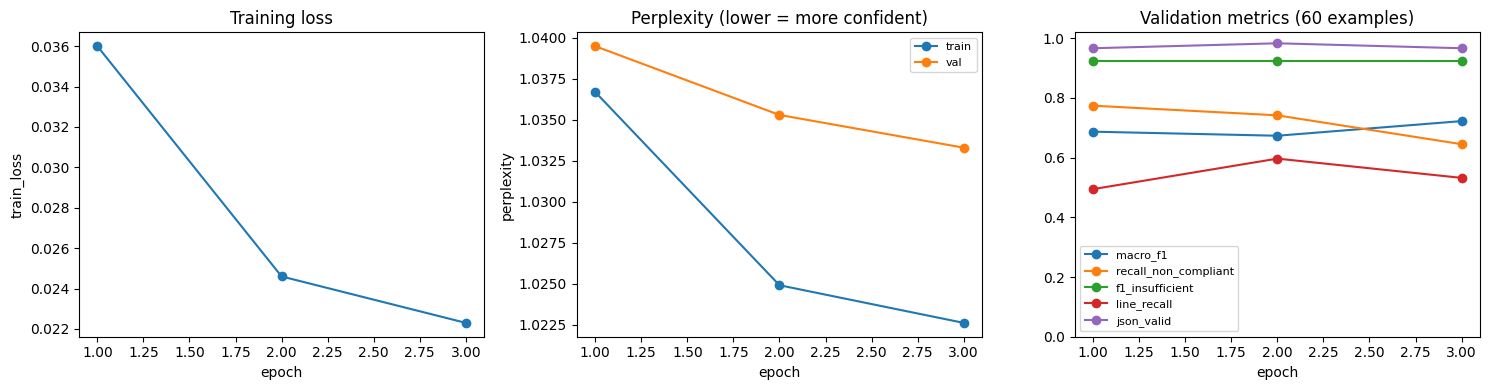

Best so far: epoch 3 (macro_f1=0.723) -> /kaggle/working/auditor_run/qwen3-4b/lora_adapter_best
--- Epoch 3/3 finished ---
Training took 201.1 min
LoRA adapter (last epoch) saved to /kaggle/working/auditor_run/qwen3-4b/lora_adapter


In [17]:
import math


def compute_perplexity(rows):
    """Teacher-forced loss on the gold JSON answer only (the prompt is masked out, like training does),
    then exponentiated: how confident the model's own probabilities already are about the exact target,
    independent of what it would generate on its own. None for always-reasoning models (no comparable
    direct target was ever trained) and in DRY_RUN (no real model). This forward-pass-with-labels path is
    new and untested on a real GPU, so it is wrapped to never break eval or training if it misbehaves."""
    if DRY_RUN or THINKING == "always" or not rows:
        return None
    try:
        set_mode(training=True)  # the same mode trainer.train() uses; inference_mode() below blocks gradients
        marker = CFG["response"]
        losses = []
        with torch.inference_mode():
            for row in rows:
                text = training_text(row)
                cut = text.index(marker) + len(marker)
                prompt_len = len(text_tokenizer(text[:cut], add_special_tokens=False).input_ids)
                ids = text_tokenizer(text, add_special_tokens=False).input_ids
                # Same policy as training (section E): examples longer than max_seq_len are skipped, not
                # truncated, since the model's position embeddings cannot go past it either way.
                if len(ids) <= prompt_len or len(ids) > CFG["max_seq_len"]:
                    continue
                input_ids = torch.tensor([ids], device="cuda")
                labels = torch.tensor([[-100] * prompt_len + ids[prompt_len:]], device="cuda")
                losses.append(model(input_ids=input_ids, labels=labels).loss.item())
        return round(math.exp(sum(losses) / len(losses)), 4) if losses else None
    except Exception as exc:
        print(f"Perplexity computation failed ({exc!r}); reporting None.")
        return None


if not RUN_TRAINING:
    log("RUN_TRAINING = False: skipping fine-tuning.")
else:
    log("=== E. Fine-tuning ===")
    # Progress tracking, shared by DRY_RUN and real training: a val subset is scored after every epoch and
    # plotted live; the adapter from the best epoch (by macro_f1) is kept apart from the last-epoch one below,
    # in case more epochs start overfitting before training reaches the end.
    EPOCH_METRICS = []
    BEST_EPOCH = {"epoch": None, "macro_f1": -1.0}
    BEST_ADAPTER_DIR = RUN_DIR / "lora_adapter_best"
    EPOCH_EVAL_ROWS = subset(SPLIT_ROWS["val"], EPOCH_EVAL_LIMIT)
    EPOCH_THINKING = eval_modes(RUN_REASONING)[-1]

    def plot_epoch_progress():
        """Redraws the whole history so far: live-updating when run interactively, and with Save & Run All
        only the last redraw survives in the saved notebook, but it still shows every epoch up to then."""
        import matplotlib.pyplot as plt
        from IPython.display import clear_output

        frame = pd.DataFrame(EPOCH_METRICS)
        clear_output(wait=True)
        display(frame[["epoch", "train_loss", "train_perplexity", "eval_perplexity", "accuracy", "macro_f1",
                       "precision_non_compliant", "recall_non_compliant", "f1_insufficient", "line_recall",
                       "line_f1", "json_valid"]])
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        axes[0].plot(frame["epoch"], frame["train_loss"], "o-")
        axes[0].set(xlabel="epoch", ylabel="train_loss", title="Training loss")
        axes[1].plot(frame["epoch"], frame["train_perplexity"], "o-", label="train")
        axes[1].plot(frame["epoch"], frame["eval_perplexity"], "o-", label="val")
        axes[1].set(xlabel="epoch", ylabel="perplexity", title="Perplexity (lower = more confident)")
        axes[1].legend(fontsize=8)
        for col in ["macro_f1", "recall_non_compliant", "f1_insufficient", "line_recall", "json_valid"]:
            axes[2].plot(frame["epoch"], frame[col], "o-", label=col)
        axes[2].set(xlabel="epoch", ylim=(0, 1.02), title=f"Validation metrics ({len(EPOCH_EVAL_ROWS)} examples)")
        axes[2].legend(fontsize=8)
        plt.tight_layout()
        (RUN_DIR / "plots").mkdir(parents=True, exist_ok=True)
        plt.savefig(RUN_DIR / "plots" / "epoch_progress.png", dpi=120, bbox_inches="tight")
        plt.show()
        if BEST_EPOCH["epoch"] is not None:
            print(f"Best so far: epoch {BEST_EPOCH['epoch']} (macro_f1={BEST_EPOCH['macro_f1']:.3f}) -> {BEST_ADAPTER_DIR}")

    def record_epoch(epoch, train_loss):
        metrics = {**run_eval(f"epoch{epoch}", "val", EPOCH_EVAL_ROWS, EPOCH_THINKING),
                   "epoch": epoch, "train_loss": train_loss,
                   "train_perplexity": round(math.exp(train_loss), 4) if train_loss is not None else None,
                   "eval_perplexity": compute_perplexity(EPOCH_EVAL_ROWS)}
        EPOCH_METRICS.append(metrics)
        if metrics["macro_f1"] is not None and metrics["macro_f1"] > BEST_EPOCH["macro_f1"]:
            BEST_EPOCH["epoch"], BEST_EPOCH["macro_f1"] = epoch, metrics["macro_f1"]
            if not DRY_RUN:
                model.save_pretrained(str(BEST_ADAPTER_DIR))
                tokenizer.save_pretrained(str(BEST_ADAPTER_DIR))
        plot_epoch_progress()

    if DRY_RUN:
        log(f"DRY RUN: would fine-tune on {len(train_texts)} examples for {NUM_EPOCHS} epochs.")
        for epoch in range(1, max(1, round(NUM_EPOCHS)) + 1):
            log(f"--- Epoch {epoch}/{NUM_EPOCHS} started (DRY RUN) ---")
            record_epoch(epoch, train_loss=round(1.0 / epoch, 4))  # a fake decreasing loss, just to exercise the plot
            log(f"--- Epoch {epoch}/{NUM_EPOCHS} finished (DRY RUN) ---")
    else:
        from datasets import Dataset
        from transformers import TrainerCallback
        from trl import SFTConfig, SFTTrainer
        from unsloth.chat_templates import train_on_responses_only

        class EpochMetricsCallback(TrainerCallback):
            """After every epoch: scores a val subset, updates the live chart, and snapshots the best epoch so
            far. Wrapped in try/except so a generation hiccup cannot lose hours of training."""

            def on_epoch_begin(self, args, state, control, **kwargs):
                log(f"--- Epoch {len(EPOCH_METRICS) + 1}/{NUM_EPOCHS} started ---")
                return control

            def on_epoch_end(self, args, state, control, **kwargs):
                try:
                    set_mode(training=False)
                    losses = [h["loss"] for h in state.log_history if "loss" in h]
                    record_epoch(len(EPOCH_METRICS) + 1, round(losses[-1], 4) if losses else None)
                    log(f"--- Epoch {len(EPOCH_METRICS)}/{NUM_EPOCHS} finished ---")
                except Exception as exc:
                    print(f"Epoch eval failed ({exc!r}); continuing training without it.")
                finally:
                    set_mode(training=True)
                return control

        set_mode(training=True)
        text_tokenizer.padding_side = "right"
        effective_batch = CFG["batch"] * CFG["grad_accum"]
        total_steps = math.ceil(len(train_texts) / effective_batch * NUM_EPOCHS)
        trainer = SFTTrainer(
            model=model,
            tokenizer=tokenizer,
            train_dataset=Dataset.from_dict({"text": train_texts}),
            callbacks=[EpochMetricsCallback()],
            args=SFTConfig(
                dataset_text_field="text",
                max_length=CFG["max_seq_len"],
                per_device_train_batch_size=CFG["batch"],
                gradient_accumulation_steps=CFG["grad_accum"],
                num_train_epochs=NUM_EPOCHS,
                learning_rate=LEARNING_RATE,
                warmup_steps=max(1, int(0.05 * total_steps)),
                lr_scheduler_type="linear",
                optim="adamw_8bit",
                weight_decay=0.001,
                logging_steps=10,
                save_strategy="epoch",
                save_total_limit=1,
                output_dir=str(RUN_DIR / "checkpoints"),
                report_to="none",
                seed=SEED,
                padding_free=False,
                dataset_num_proc=1,
            ),
        )
        trainer = train_on_responses_only(trainer, instruction_part=CFG["instruction"], response_part=CFG["response"])
        labels = trainer.train_dataset[0]["labels"]
        trained_tokens = sum(1 for x in labels if x != -100)
        print(f"Example 0: loss on {trained_tokens} of {len(labels)} tokens (the answer only)")
        assert 0 < trained_tokens < len(labels), "masking the prompt failed"
        log(f"{total_steps} optimizer steps, effective batch {effective_batch}")
        log(f"=== Starting training: {NUM_EPOCHS} epochs over {len(train_texts)} examples ===")
        stats = trainer.train()
        log(f"Training took {stats.metrics['train_runtime'] / 60:.1f} min")
        pd.DataFrame(trainer.state.log_history).to_csv(RUN_DIR / "train_log.csv", index=False)
        model.save_pretrained(str(ADAPTER_DIR))
        tokenizer.save_pretrained(str(ADAPTER_DIR))
        shutil.rmtree(RUN_DIR / "checkpoints", ignore_errors=True)  # only needed to recover from a crash
        log("LoRA adapter (last epoch) saved to", ADAPTER_DIR)

    if EPOCH_METRICS:
        pd.DataFrame(EPOCH_METRICS).to_csv(RUN_DIR / "epoch_metrics.csv", index=False)
        if BEST_EPOCH["epoch"] not in (None, len(EPOCH_METRICS)):
            print(f"Best val macro_f1 was at epoch {BEST_EPOCH['epoch']}, not the last one ({len(EPOCH_METRICS)}). "
                  f"{BEST_ADAPTER_DIR} has that epoch's adapter; {ADAPTER_DIR} has the last epoch's.")

## F. Final evaluation

The trained model runs on the same examples as the baseline, so the numbers compare directly. With `TEMPERATURE_SWEEP`, it also picks its own temperature on `val`. Below are also the confusion matrix, the accuracy per category, a few mistakes, a precision/recall/f1 table for each label, and 2-3 full examples of correct answers (also written to `example_runs.md`).

=== F. Final evaluation ===
[finetuned | direct | test | temperature 0.0] 373 examples
  147/373 answers, 470s
  307/373 answers, 723s
  373/373 answers, 807s
  macro_f1=0.8018 | line_recall=0.7572 | json_valid=0.9973 | 2.16 s/example
[finetuned | direct | test_ood | temperature 0.0] 356 examples
  149/356 answers, 606s
  309/356 answers, 886s
  356/356 answers, 945s
  macro_f1=0.8168 | line_recall=0.4811 | json_valid=1.0 | 2.66 s/example


,model,mode,split,temperature,n,accuracy,exact_match,macro_f1,recall_non_compliant,precision_non_compliant,f1_insufficient,line_recall,line_precision,line_f1,hallucinated_citations,json_valid,seconds_per_example
0,epoch1,direct,val,0.0,60,0.6333,0.4500,0.6871,0.7742,0.6486,0.9231,0.4946,0.5083,0.5014,0.0152,0.9667,2.68
1,epoch2,direct,val,0.0,60,0.6167,0.5000,0.6735,0.7419,0.6216,0.9231,0.5968,0.5944,0.5956,0.0156,0.9833,2.87
2,epoch3,direct,val,0.0,60,0.6500,0.5500,0.7225,0.6452,0.6897,0.9231,0.5323,0.5460,0.5391,0.0152,0.9667,2.76
3,finetuned,direct,test,0.0,373,0.7721,0.6997,0.8018,0.8057,0.7421,0.9189,0.7572,0.7568,0.7570,0.0142,0.9973,2.16
4,finetuned,direct,test_ood,0.0,356,0.7978,0.5843,0.8168,0.8750,0.7159,0.9620,0.4811,0.4802,0.4806,0.0494,1.0000,2.66


macro_f1 by model:


,model,epoch1,epoch2,epoch3,finetuned
split,mode,,,,
test,direct,NaN,NaN,NaN,0.8018
test_ood,direct,NaN,NaN,NaN,0.8168
val,direct,0.6871,0.6735,0.7225,NaN


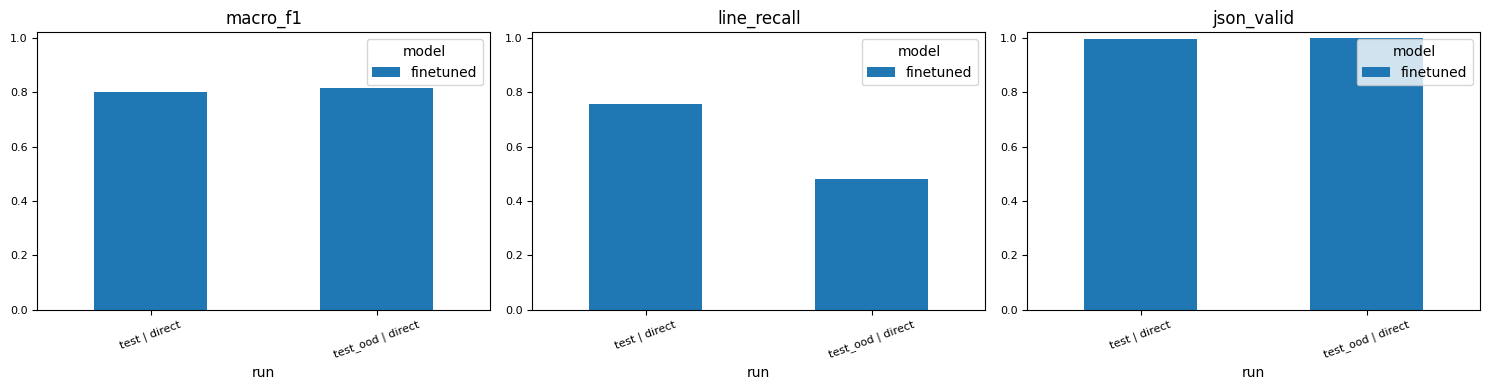

Written: /kaggle/working/auditor_run/qwen3-4b/plots/baseline_vs_finetuned.png
Confusion matrix on test (rows = KICS label, columns = model answer):


,compliant,non_compliant,insufficient_evidence,invalid
compliant,96,44,1,0
non_compliant,32,141,2,0
insufficient_evidence,0,5,51,1


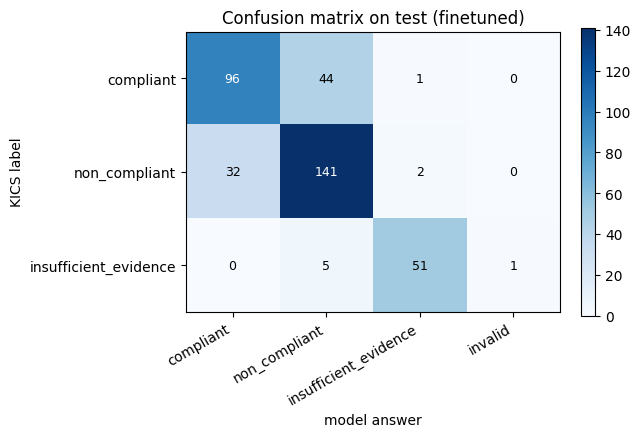

Written: /kaggle/working/auditor_run/qwen3-4b/plots/confusion_matrix.png
Precision / recall / f1 per label on test:


,precision,recall,f1,n
compliant,0.7500,0.6809,0.7138,141.0
non_compliant,0.7421,0.8057,0.7726,175.0
insufficient_evidence,0.9444,0.8947,0.9189,57.0


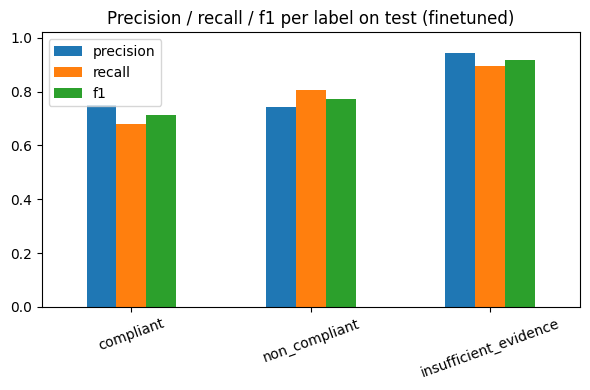

Written: /kaggle/working/auditor_run/qwen3-4b/plots/per_label_metrics.png
Unsloth: Will smartly offload gradients to save VRAM!
Perplexity on test (teacher-forced, direct target): 1.0303


,category,n,accuracy
9,Build Process,2,0.000
6,Networking and Firewall,52,0.538
5,Encryption,40,0.725
8,Resource Management,11,0.727
4,Availability,21,0.810
1,Access Control,90,0.811
0,Secret Management,16,0.812
2,Observability,69,0.812
3,Insecure Configurations,45,0.867
7,Best Practices,27,0.926


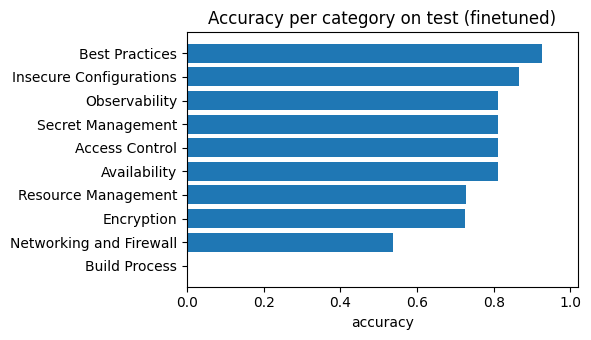

Written: /kaggle/working/auditor_run/qwen3-4b/plots/accuracy_per_category.png
85 wrong answers on test; a few of them:
-------------------------------------------------------------------------------- 
89143358-cec6-49f5-9392-920c591c669c:negative2.tf | KICS: compliant | model: non_compliant
{"status": "non_compliant", "citations": [{"file": "main.tf", "line": 3, "code": "require_uppercase_characters = false"}], "rationale": "Requirement not met at line(s) 3: Ram Account Password Policy should have 'require_lowercase_characters' set to true"}
-------------------------------------------------------------------------------- 
5e0fb613-ba9b-44c3-88f0-b44188466bfd:negative2.tf | KICS: compliant | model: non_compliant
{"status": "non_compliant", "citations": [{"file": "main.tf", "line": 3, "code": "require_lowercase_characters = false"}], "rationale": "Requirement not met at line(s) 3: Ram Account Password Policy should have 'require_uppercase_characters' set to true"}
-----------------------

In [18]:
require_defined("EVAL_SPLITS", "SPLIT_ROWS", "subset", "run_eval", "tune_temperature", "eval_modes", "results_table", "to_markdown", "PREDICTIONS", "RESULTS")
import matplotlib.pyplot as plt
import numpy as np

plots_dir = RUN_DIR / "plots"
plots_dir.mkdir(parents=True, exist_ok=True)
if RUN_FINAL_EVAL and (RUN_TRAINING or DRY_RUN):
    log("=== F. Final evaluation ===")
    tune_temperature(MODEL_TAG)
    for split in EVAL_SPLITS:
        for thinking in eval_modes(MODEL_TAG == "finetuned_reasoning"):
            limit = THINKING_EVAL_LIMIT if thinking else EVAL_LIMIT
            run_eval(MODEL_TAG, split, subset(SPLIT_ROWS[split], limit), thinking)

if not (RUN_FINAL_EVAL and (RUN_TRAINING or DRY_RUN)):
    log("RUN_FINAL_EVAL = False (or nothing was trained): skipping final evaluation.")
table = results_table()
display(table)
if not table.empty:
    (RUN_DIR / "results.md").write_text(to_markdown(table), encoding="utf-8")
    print("macro_f1 by model:")
    display(table.pivot_table(index=["split", "mode"], columns="model", values="macro_f1"))

    compare = table[table["model"].isin(["baseline", MODEL_TAG]) & table["split"].isin(EVAL_SPLITS)].copy()
    if not compare.empty:
        compare["run"] = compare["split"] + " | " + compare["mode"]
        metrics_to_plot = ["macro_f1", "line_recall", "json_valid"]
        fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(5 * len(metrics_to_plot), 4))
        for ax, metric in zip(np.atleast_1d(axes), metrics_to_plot):
            pivot = compare.pivot_table(index="run", columns="model", values=metric)
            pivot = pivot[[m for m in ["baseline", MODEL_TAG] if m in pivot.columns]]
            pivot.plot(kind="bar", ax=ax, ylim=(0, 1.02), title=metric, fontsize=8)
            ax.tick_params(axis="x", rotation=20)
        plt.tight_layout()
        plt.savefig(plots_dir / "baseline_vs_finetuned.png", dpi=120, bbox_inches="tight")
        plt.show()
        print("Written:", plots_dir / "baseline_vs_finetuned.png")

final_key = (MODEL_TAG, "thinking" if eval_modes(MODEL_TAG == "finetuned_reasoning")[-1] else "direct", "test")
if final_key in PREDICTIONS:
    rows, parsed = PREDICTIONS[final_key]
    final_metrics = next(m for m in RESULTS if (m["model"], m["mode"], m["split"]) == final_key)
    print("Confusion matrix on test (rows = KICS label, columns = model answer):")
    conf = pd.DataFrame(final_metrics["confusion"]).T
    display(conf)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    im = ax.imshow(conf.values, cmap="Blues")
    ax.set_xticks(range(len(conf.columns)))
    ax.set_xticklabels(conf.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(conf.index)))
    ax.set_yticklabels(conf.index)
    ax.set(xlabel="model answer", ylabel="KICS label", title=f"Confusion matrix on test ({MODEL_TAG})")
    vmax = conf.values.max() if conf.values.size else 0
    for i in range(len(conf.index)):
        for j in range(len(conf.columns)):
            ax.text(j, i, conf.values[i, j], ha="center", va="center", fontsize=9,
                   color="white" if conf.values[i, j] > vmax / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.savefig(plots_dir / "confusion_matrix.png", dpi=120, bbox_inches="tight")
    plt.show()
    print("Written:", plots_dir / "confusion_matrix.png")
    print("Precision / recall / f1 per label on test:")
    display(pd.DataFrame(final_metrics["per_label"]).T[["precision", "recall", "f1", "n"]])
    per_label_df = pd.DataFrame(final_metrics["per_label"]).T[["precision", "recall", "f1"]]
    fig, ax = plt.subplots(figsize=(6, 4))
    per_label_df.plot(kind="bar", ax=ax, ylim=(0, 1.02),
                      title=f"Precision / recall / f1 per label on test ({MODEL_TAG})")
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.savefig(plots_dir / "per_label_metrics.png", dpi=120, bbox_inches="tight")
    plt.show()
    print("Written:", plots_dir / "per_label_metrics.png")
    final_perplexity = compute_perplexity(rows)
    if final_perplexity is not None:
        print(f"Perplexity on test (teacher-forced, direct target): {final_perplexity}")
    per_category = collections.defaultdict(lambda: [0, 0])
    for row, (_, answer) in zip(rows, parsed):
        per_category[row["category"]][0] += int((answer or {}).get("status") == row["label"])
        per_category[row["category"]][1] += 1
    category_df = pd.DataFrame([{"category": c, "n": n, "accuracy": round(ok / n, 3)}
                                for c, (ok, n) in per_category.items()]).sort_values("accuracy")
    display(category_df)
    fig, ax = plt.subplots(figsize=(6, max(3, 0.35 * len(category_df))))
    ax.barh(category_df["category"], category_df["accuracy"])
    ax.set(xlim=(0, 1.02), xlabel="accuracy", title=f"Accuracy per category on test ({MODEL_TAG})")
    plt.tight_layout()
    plt.savefig(plots_dir / "accuracy_per_category.png", dpi=120, bbox_inches="tight")
    plt.show()
    print("Written:", plots_dir / "accuracy_per_category.png")
    wrong = [(row, answer) for row, (_, answer) in zip(rows, parsed) if (answer or {}).get("status") != row["label"]]
    print(f"{len(wrong)} wrong answers on test; a few of them:")
    for row, answer in wrong[:3]:
        print("-" * 80, f"\n{row['sample_id']} | KICS: {row['label']} | model: {(answer or {}).get('status')}")
        print(json.dumps(answer)[:400] if answer else "(no valid JSON)")

    # 2-3 example runs of the fine-tuned model: one correctly-answered example per label, for the report/demo.
    examples, md_blocks = [], ["# Example answers from the fine-tuned model\n"]
    for label in LABELS:
        correct = [(row, answer) for row, (_, answer) in zip(rows, parsed)
                   if row["label"] == label and (answer or {}).get("status") == label]
        if correct:
            examples.append(random.Random(SEED).choice(correct))
    print(f"\n{len(examples)} example run(s) of the fine-tuned model (one per label, when answered correctly):")
    for row, answer in examples:
        evidence = row["messages"][1]["content"]
        print("-" * 80, f"\n{row['sample_id']} | KICS label: {row['label']}")
        print(evidence[:500] + ("..." if len(evidence) > 500 else ""))
        print("Model answer:", json.dumps(answer, ensure_ascii=False))
        md_blocks.append(f"## {row['sample_id']} (KICS label: {row['label']})\n\n"
                         f"**Requirement + evidence:**\n```\n{evidence}\n```\n\n"
                         f"**Model answer:**\n```json\n{json.dumps(answer, indent=2, ensure_ascii=False)}\n```\n")
    (RUN_DIR / "example_runs.md").write_text("\n".join(md_blocks), encoding="utf-8")
    print("Written:", RUN_DIR / "example_runs.md")

## G. Export for Ollama

Unsloth merges the adapter with the base model and writes a GGUF file:
- **Q4_K_M:** about 2.5 GB for a 4B model and 5 GB for an 8B one;
- **Q8_0 for Gemma 3:** Unsloth does not have Q4 for Gemma yet.

It also writes a `Modelfile` with the chat template used for training. The conversion happens in `/tmp`, so the intermediate files (llama.cpp and the merged model) do not end up in the output. Only the GGUF and the `Modelfile` are copied to the output. 14B models are not exported, since they do not run on a laptop with 4 GB VRAM.

In the `Modelfile`, the generation settings (temperature, top_p, top_k) are replaced with the ones from the final evaluation. Otherwise, Unsloth's own values would stay, e.g. temperature 1.5 for Llama 3.1 and Phi-4, and the model would answer far more randomly than in the evaluation. With `RUN_TRAINING = False` nothing is exported: only a `Modelfile` is written for the original model in Ollama, with the system prompt and temperature evaluated here.

If the export fails, the LoRA adapter stays saved in `lora_adapter/`.

In [19]:
require_defined("eval_modes", "decoding")
log("=== G. Export for Ollama ===")
GGUF_DIR = RUN_DIR / "gguf"
FINAL_THINKING = eval_modes(MODEL_TAG == "finetuned_reasoning")[-1]
# Ollama gets the decoding of the final evaluation; Unsloth's Modelfiles set their own (temperature 1.5 for Llama 3.1).
OLLAMA_PARAMETERS = "\n".join(f"PARAMETER {k} {v}" for k, v in decoding(FINAL_THINKING).items()
                              if k in ("temperature", "top_p", "top_k", "min_p"))


def with_decoding(modelfile):
    modelfile = re.sub(r"(?m)^PARAMETER\s+(temperature|top_p|top_k|min_p)\b.*\n?", "", modelfile)
    return modelfile.rstrip("\n") + "\n" + OLLAMA_PARAMETERS + "\n"


def recent_files(root, since):
    found = []
    for path in Path(root).rglob("*"):
        try:
            if path.is_file() and path.stat().st_mtime >= since and not {"llama.cpp", "kics_repo"} & set(path.parts):
                found.append(path)
        except OSError:
            pass
    return found


if not (RUN_GGUF_EXPORT and RUN_TRAINING and CFG["gguf"]):
    print("GGUF export skipped (RUN_GGUF_EXPORT / RUN_TRAINING / preset).")
elif DRY_RUN:
    print("DRY RUN: skipping the GGUF export.")
else:
    export_dir = Path("/tmp/gguf_export")
    t0, cwd = time.time(), os.getcwd()
    os.chdir("/tmp")  # llama.cpp is cloned and built in the working directory
    try:
        model.save_pretrained_gguf(str(export_dir), tokenizer, quantization_method=CFG["gguf"])
    except Exception as exc:
        print("GGUF export failed:", repr(exc)[:1500])
    finally:
        os.chdir(cwd)
    produced = [p for p in recent_files("/tmp", t0) if p.suffix == ".gguf" or p.name == "Modelfile"]
    ggufs = [p for p in produced if p.suffix == ".gguf"]
    chosen = [p for p in ggufs if CFG["gguf"].lower() in p.name.lower()] or sorted(ggufs, key=lambda p: p.stat().st_size)[:1]
    if chosen:
        GGUF_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy2(chosen[0], GGUF_DIR / chosen[0].name)
        print(f"{chosen[0].name}: {chosen[0].stat().st_size / 1e9:.2f} GB")
        modelfiles = [p for p in produced if p.name == "Modelfile"]
        if modelfiles:
            text = modelfiles[0].read_text(encoding="utf-8")
            text = re.sub(r"(?m)^FROM .*$", f"FROM ./{chosen[0].name}", text, count=1)
            (GGUF_DIR / "Modelfile").write_text(with_decoding(text), encoding="utf-8")
            print("Modelfile written; decoding:", OLLAMA_PARAMETERS.replace("\n", " | "))

gguf_files = sorted(GGUF_DIR.glob("*.gguf")) if GGUF_DIR.exists() else []
gguf_name = gguf_files[0].name if gguf_files else "<model>.gguf"
has_modelfile = (GGUF_DIR / "Modelfile").exists()
think_flag = "" if THINKING == "none" else f" --think={str(FINAL_THINKING).lower()}"
message_format = f"""System prompt:

```
{SYSTEM_PROMPT}
```

User message (an example from test):

```
{SPLIT_ROWS["test"][0]["messages"][1]["content"]}
```
"""
if RUN_TRAINING:
    readme = f"""# The trained model in Ollama ({PRESET})

## Files
- `gguf/{gguf_name}`: the trained model, quantized {CFG['gguf'] or '-'}{'' if gguf_files else ' (missing: the export was skipped or failed)'}
- `gguf/Modelfile`: the settings for Ollama{'' if has_modelfile else ' (not generated; see step 2b)'}
- `lora_adapter/`: the LoRA adapter, for Unsloth / transformers

## Steps on the laptop
1. Put `{gguf_name}` and `Modelfile` in the same folder.
2. `ollama create compliance-auditor -f Modelfile`
   - 2b. If `Modelfile` is missing: `ollama show {CFG['ollama']} --modelfile > Modelfile`, then replace the `FROM ...` line with `FROM ./{gguf_name}` and the `PARAMETER temperature / top_p / top_k / min_p` lines with the settings below.
3. `ollama run compliance-auditor{think_flag}`

## Generation settings

These are the ones from the final evaluation in the notebook{' and they are already written into `Modelfile`' if has_modelfile else ''}. Without them, Ollama uses the template's values (e.g. temperature 1.5 for Llama 3.1, in the Modelfile written by Unsloth), and the answers become far more random.

```
{OLLAMA_PARAMETERS}
```

## Use exactly the training format

{message_format}"""
else:
    # Nothing was trained: the "model" is the original one, plus the system prompt and the decoding evaluated here.
    (RUN_DIR / "Modelfile").write_text(
        f'FROM {CFG["ollama"]}\n{OLLAMA_PARAMETERS}\nSYSTEM """{SYSTEM_PROMPT}"""\n', encoding="utf-8")
    readme = f"""# The base model in Ollama ({PRESET}), without fine-tuning

This run did not train anything, so the model is the original one. `Modelfile` (next to this file) adds the system prompt and the generation settings it was evaluated with in the notebook.

## Steps on the laptop
1. `ollama pull {CFG['ollama']}`
2. In the folder with `Modelfile`: `ollama create compliance-auditor-base -f Modelfile`
3. `ollama run compliance-auditor-base{think_flag}`

## Generation settings

```
{OLLAMA_PARAMETERS}
```

## Message format

{message_format}"""
(RUN_DIR / "OLLAMA_README.md").write_text(readme, encoding="utf-8")
print("Written:", RUN_DIR / "OLLAMA_README.md")


=== G. Export for Ollama ===
Unsloth: Merging model weights to 16-bit format...


config.json:   0%|          | 0.00/752 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model-00001-of-00002.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Preparing safetensor model files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

... (2 outputs left out)

Unsloth: Preparing safetensor model files: 100%|██████████| 2/2 [00:38<00:00, 19.18s/it]


Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [00:50<00:00, 25.39s/it]


Unsloth: Merge process complete. Saved to `/tmp/gguf_export`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b12340-mix-6186f42 (app-b12340-mix-6186f42-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['/tmp/gguf_export_gguf/Qwen3-4B.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: Model files cleanup...
Unsloth: All GGUF conversions completed successfully!
Gene

In [20]:
import zipfile

log("=== Packaging results into a zip ===")
archive = WORK_DIR / f"auditor_{PRESET}_results.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(RUN_DIR.rglob("*")):
        if path.is_file() and not {"gguf", "checkpoints"} & set(path.relative_to(RUN_DIR).parts):
            zf.write(path, path.relative_to(RUN_DIR.parent))
print(f"{archive.name}: {archive.stat().st_size / 1e6:.1f} MB (everything except the GGUF, which is downloaded separately)")
print("Contents of", RUN_DIR)
for path in sorted(RUN_DIR.iterdir()):
    size = sum(p.stat().st_size for p in path.rglob("*") if p.is_file()) if path.is_dir() else path.stat().st_size
    print(f"  {path.name:28s} {size / 1e6:9.1f} MB")

=== Packaging results into a zip ===
auditor_qwen3-4b_results.zip: 130.5 MB (everything except the GGUF, which is downloaded separately)
Contents of /kaggle/working/auditor_run/qwen3-4b
  OLLAMA_README.md                   0.0 MB
  epoch1                             0.0 MB
  epoch2                             0.0 MB
  epoch3                             0.0 MB
  epoch_metrics.csv                  0.0 MB
  example_runs.md                    0.0 MB
  finetuned                          0.4 MB
  gguf                            2497.3 MB
  lora_adapter                      82.0 MB
  lora_adapter_best                 82.0 MB
  metrics.json                       0.0 MB
  plots                              0.2 MB
  results.md                         0.0 MB
  run_log.txt                        0.0 MB
  train_log.csv                      0.0 MB


## Common issues

| Symptom | Cause and fix |
|---|---|
| Installation fails, *Could not resolve host* | Internet is off: *Settings* → *Internet: On* (phone-verified account). |
| *CUDA capability 7.0+* | You picked P100. Pick **GPU T4 x2**. |
| *CUDA out of memory* during training | In `PRESETS`: `batch=1`, `grad_accum=16`, or a smaller `max_seq_len`. |
| *CUDA out of memory* during generation (baseline, per-epoch, evaluation) | The model plus one generation, even on a couple of examples, can fill a T4 by themselves. The small presets (including `qwen3-4b`) now load the model in 4-bit; if it still happens, also lower `batch`/`max_seq_len` as above. |
| *Expected all tensors to be on the same device* (e.g. `embed_tokens` on CPU, the rest on CUDA) | Usually follows a *CUDA out of memory* in the same session: the tensors from the failed attempt stay in GPU memory (Python does not free them, because of the traceback), and the model is reloaded onto a GPU that is already busy. **Restart the kernel** (*Run* → *Restart Session*, not just re-running the cells) before trying again. |
| *masking the prompt failed* | The preset's user/assistant markers do not match the installed chat template. Send the cell with the error. |
| The first steps are very slow on `qwen3.5-4b` | Normal: the Triton kernels are compiling. On a T4 it stays about 3x slower than Qwen3-4B. |
| Evaluation takes a long time on `deepseek-r1-8b` | Every answer includes the reasoning. Lower `THINKING_EVAL_LIMIT` or `REASONING_SAMPLES`. |
| *No correct reasoning traces were kept* | The reasoning got cut off by the token limit. Raise `THINKING_MAX_NEW_TOKENS` (or `think_tokens` in the preset). |
| The GGUF export fails | The LoRA adapter is saved in `lora_adapter/`. The rest of the results are complete. |
| Good answers here, but weak in Ollama | A different chat template or system prompt. Use the generated `Modelfile` and the system prompt from `OLLAMA_README.md`. |
| The interactive session stopped | Interactive sessions close after being idle. Long runs should use *Save Version* → *Save & Run All*. |

**Comparing models:** run the notebook again with a different `PRESET`. For each model you download `auditor_<preset>_results.zip`. The `results.md` tables have the same columns, so they can be placed side by side in the report.